# Modelo computacional de PLN e clusterização para identificação e caracterização de perfis em periódicos científicos

Esta versão organiza o processamento em uma pipeline de PLN e Aprendizado Não Supervisionado aplicada aos artigos científicos e acrescenta uma caracterização multidimensional dos documentos.

As representações avaliadas são **Bag of Words (BoW)**, **TF-IDF**, **embeddings contextuais**, **estrutura documental** e uma representação **híbrida de embeddings + estrutura documental**. A representação híbrida combina o conteúdo semântico dos artigos com indicadores como extensão do texto, densidade de figuras e tabelas, citações, referências, equações e presença de seções.

Os algoritmos avaliados são **K-means**, **Agrupamento Hierárquico** e **DBSCAN**. Para dados textuais, a avaliação principal utiliza **Silhouette com distância de cosseno**. Davies-Bouldin e Calinski-Harabasz são mantidos como métricas complementares.

Além da clusterização, cada artigo recebe indicadores exploratórios de perfil metodológico — **teórico, qualitativo, quantitativo, experimental e revisão** — obtidos por similaridade semântica com descrições prototípicas. Esses perfis não entram na formação dos clusters; são utilizados posteriormente para interpretar os grupos encontrados e preservar o caráter não supervisionado da descoberta de perfis.

## 1. Instalação e importações

In [ ]:
!pip -q install sentence-transformers pymupdf

import json
import re
from collections import Counter
from pathlib import Path

import fitz
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd

from IPython.display import display
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize
from scipy import sparse
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import Normalizer, StandardScaler
from sentence_transformers import SentenceTransformer

for recurso in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(recurso, quiet=True)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.9/68.9 MB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 34.7 MB/s eta 0:00:00


/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


## 2. Configuração

In [ ]:
CAMINHO_BASE_PDFS = "/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 - Novos Artigos"
PASTA_RAIZ_PERIODICOS = "0 - Novos Artigos"

CANDIDATOS_CSV = [
    "/content/drive/MyDrive/ARTIGOS SELECIONADOS/extracao_textos_artigos_pdfs.csv",
    "/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 - Novos Artigos/extracao_textos_artigos_pdfs.csv",
    "/content/extracao_textos_artigos_pdfs.csv"
]

SAIDA_DIR = Path("/content/drive/MyDrive/ARTIGOS SELECIONADOS/resultados_modelo_perfis")
COLUNA_TEXTO = "texto"
COLUNA_ID = "arquivo"
COLUNA_STATUS = "status"
COLUNA_PERIODICO = "periodico"

ANO_MIN = 2021
ANO_MAX = 2027

RANDOM_STATE = 42
K_MIN = 2
K_MAX = 10
MIN_COBERTURA_DBSCAN = 0.70
MIN_CLUSTER_FRAC = 0.02

NORMALIZACAO_LEXICAL = "lemma"
MAX_FEATURES = 6000
MIN_DF = 3
MAX_DF = 0.95

MODELO_EMBEDDING = "sentence-transformers/all-MiniLM-L6-v2"
PALAVRAS_POR_CHUNK = 250
MAX_CHUNKS_EMBEDDING = 16
BATCH_SIZE_EMBEDDING = 32

PESO_EMBEDDING_HIBRIDO = 1.0
PESO_ESTRUTURA_HIBRIDO = 1.0
EXTRAIR_METRICAS_VISUAIS_PDF = True
MIN_AREA_RELATIVA_BLOCO_IMAGEM = 0.002

TOP_KEYWORDS = 30
TOP_KEYWORDS_PERIODICO = 20
TOP_KEYWORDS_CLUSTER = 15
TOP_TERMOS_CLUSTER = 20

EXECUTAR_COMPARACAO_ESCOPO = True

SAIDA_DIR.mkdir(parents=True, exist_ok=True)

## 3. Carregamento do corpus e identificação do periódico

O arquivo `extracao_textos_artigos_pdfs.csv` possui o caminho completo do PDF na coluna `arquivo`. Como os documentos estão organizados no formato:

`MyDrive/ARTIGOS SELECIONADOS/0 - Novos Artigos/Nome do periódico/subpastas/arquivo.pdf`

o nome do periódico é recuperado como a primeira pasta localizada após `0 - Novos Artigos`. Assim, a existência de subpastas dentro de cada periódico não interfere na identificação.

In [ ]:
from google.colab import drive
import os
import shutil
import subprocess

try:
    drive.flush_and_unmount()
except:
    pass

subprocess.run(["fusermount", "-u", "/content/drive"], capture_output=True)
subprocess.run(["umount", "/content/drive"], capture_output=True)

if os.path.exists("/content/drive"):
    shutil.rmtree("/content/drive")

os.makedirs("/content/drive", exist_ok=True)

drive.mount("/content/drive")

Drive not mounted, so nothing to flush and unmount.
Mounted at /content/drive


In [ ]:
caminho_csv = next((p for p in CANDIDATOS_CSV if Path(p).exists()), None)

if caminho_csv is None:
    raise FileNotFoundError(
        "O arquivo extracao_textos_artigos_pdfs.csv não foi encontrado. "
        "Ajuste CANDIDATOS_CSV para o local em que o arquivo foi salvo."
    )

df = pd.read_csv(caminho_csv)

if COLUNA_TEXTO not in df.columns:
    raise ValueError(f"A coluna '{COLUNA_TEXTO}' não foi encontrada.")

if COLUNA_ID not in df.columns:
    raise ValueError(f"A coluna '{COLUNA_ID}' não foi encontrada.")

if COLUNA_STATUS in df.columns:
    df = df[df[COLUNA_STATUS].astype(str).str.lower().eq("ok")].copy()

df[COLUNA_TEXTO] = df[COLUNA_TEXTO].fillna("").astype(str)
df[COLUNA_ID] = df[COLUNA_ID].fillna("").astype(str)

df = df[df[COLUNA_TEXTO].str.strip().ne("")].copy()
df = df.drop_duplicates(subset=[COLUNA_ID]).reset_index(drop=True)

def extrair_periodico_caminho(caminho):
    partes = Path(str(caminho).replace("\\", "/")).parts
    indices = [i for i, parte in enumerate(partes) if parte == PASTA_RAIZ_PERIODICOS]
    if not indices:
        return None

    indice = indices[-1]

    if indice + 1 >= len(partes):
        return None

    periodico = partes[indice + 1].strip()
    periodico = re.sub(r"\s*\(\d+\)\s*$", "", periodico).strip()

    return periodico

def extrair_subpasta_caminho(caminho):
    partes = Path(str(caminho).replace("\\", "/")).parts
    indices = [i for i, parte in enumerate(partes) if parte == PASTA_RAIZ_PERIODICOS]

    if not indices:
        return None

    indice = indices[-1]

    if indice + 2 >= len(partes):
        return ""

    return "/".join(partes[indice + 2:-1])

def extrair_ano_publicacao(texto, caminho=""):
    texto = str(texto)
    cabecalho = texto[:25000]

    padroes_prioritarios = [
        ("published_online", r"(?i)\bpublished\s+online\b.{0,100}\b(20\d{2})\b"),
        ("published", r"(?i)\bpublished\b.{0,100}\b(20\d{2})\b"),
        ("publication_date", r"(?i)\bpublication\s+date\b.{0,100}\b(20\d{2})\b"),
        ("copyright", r"(?i)(?:©|\bcopyright\b).{0,100}\b(20\d{2})\b"),
        ("citation_header", r"(?i)\b(?:vol(?:ume)?|issue|no\.?)\b.{0,120}\b(20\d{2})\b")
    ]

    for fonte, padrao in padroes_prioritarios:
        encontrados = re.findall(padrao, cabecalho)
        for ano in encontrados:
            ano = int(ano)
            if ANO_MIN <= ano <= ANO_MAX:
                return ano, fonte

    anos_cabecalho = [
        int(a)
        for a in re.findall(r"\b(20\d{2})\b", cabecalho[:8000])
        if ANO_MIN <= int(a) <= ANO_MAX
    ]

    if anos_cabecalho:
        contagem = Counter(anos_cabecalho)
        return contagem.most_common(1)[0][0], "cabecalho"

    anos_caminho = [
        int(a)
        for a in re.findall(r"\b(20\d{2})\b", str(caminho))
        if ANO_MIN <= int(a) <= ANO_MAX
    ]

    if anos_caminho:
        return anos_caminho[-1], "caminho"

    return np.nan, "nao_identificado"

df[COLUNA_PERIODICO] = df[COLUNA_ID].map(extrair_periodico_caminho)
df["subpasta"] = df[COLUNA_ID].map(extrair_subpasta_caminho)

anos_extraidos = [
    extrair_ano_publicacao(texto, caminho)
    for texto, caminho in zip(df[COLUNA_TEXTO], df[COLUNA_ID])
]

df["ano_publicacao"] = [item[0] for item in anos_extraidos]
df["fonte_ano"] = [item[1] for item in anos_extraidos]

invalidos = df[COLUNA_PERIODICO].isna() | df[COLUNA_PERIODICO].astype(str).str.strip().eq("")

if invalidos.any():
    display(df.loc[invalidos, [COLUNA_ID]].head(20))
    raise ValueError("Não foi possível identificar o periódico de todos os arquivos.")

print("CSV:", caminho_csv)
print("Artigos válidos:", len(df))
print("Periódicos identificados:", df[COLUNA_PERIODICO].nunique())
print("Anos identificados:", int(df["ano_publicacao"].notna().sum()))
print("Anos não identificados:", int(df["ano_publicacao"].isna().sum()))

display(sorted(df[COLUNA_PERIODICO].unique()))
display(df["fonte_ano"].value_counts(dropna=False).rename_axis("fonte").reset_index(name="n"))

CSV: /content/drive/MyDrive/ARTIGOS SELECIONADOS/0 - Novos Artigos/extracao_textos_artigos_pdfs.csv
Artigos válidos: 795
Periódicos identificados: 8
Anos identificados: 794
Anos não identificados: 1


['ACM Computing Surveys',
 'Computer Science Review',
 'Education and Information Technologies',
 'ICT Express',
 'IEEE Communications Surveys and Tutorials',
 'ISA Transactions',
 'Information Sciences',
 'Proceedings of the IEEE']

,fonte,n
0,copyright,484
1,published,114
2,published_online,99
3,citation_header,94
4,caminho,2
5,cabecalho,1
6,nao_identificado,1


## 4. Caracterização do corpus

,periodico,n_artigos,percentual
0,ACM Computing Surveys,100,12.578616
1,ICT Express,100,12.578616
2,Education and Information Technologies,100,12.578616
3,ISA Transactions,100,12.578616
4,Computer Science Review,100,12.578616
5,Proceedings of the IEEE,100,12.578616
6,Information Sciences,100,12.578616
7,IEEE Communications Surveys and Tutorials,95,11.949686


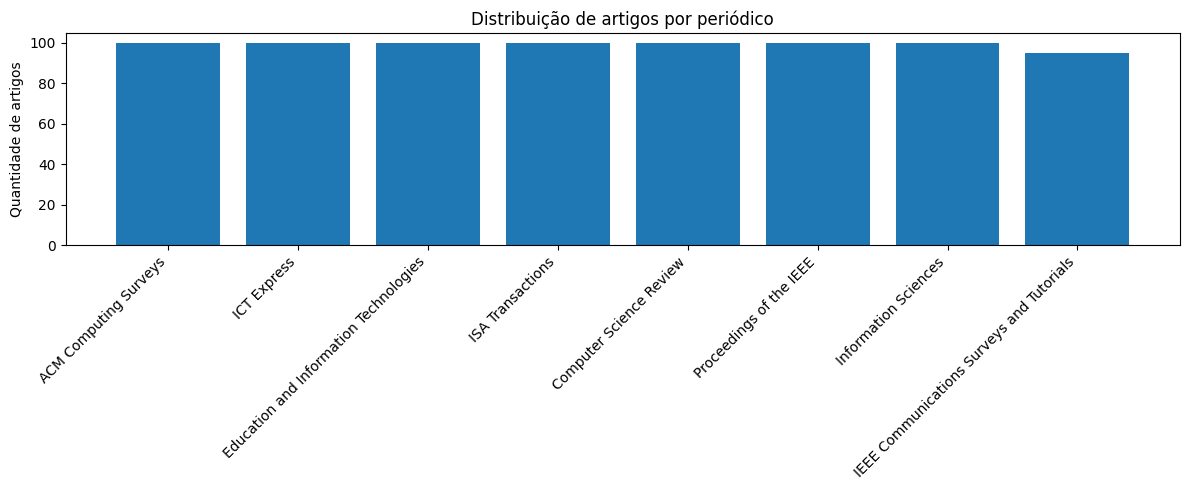

,periodico,ano_publicacao,n_artigos
0,ACM Computing Surveys,2024.0,100
1,Computer Science Review,2023.0,1
2,Computer Science Review,2024.0,24
3,Computer Science Review,2025.0,75
4,Education and Information Technologies,2025.0,100
5,ICT Express,2024.0,34
6,ICT Express,2025.0,66
7,IEEE Communications Surveys and Tutorials,2024.0,42
8,IEEE Communications Surveys and Tutorials,2025.0,53
9,ISA Transactions,2025.0,100


,periodico,anos_nao_identificados
0,Information Sciences,1


In [ ]:
distribuicao_periodicos = (
    df[COLUNA_PERIODICO]
    .value_counts()
    .rename_axis("periodico")
    .reset_index(name="n_artigos")
)

distribuicao_periodicos["percentual"] = (
    100 * distribuicao_periodicos["n_artigos"] / distribuicao_periodicos["n_artigos"].sum()
)

display(distribuicao_periodicos)

plt.figure(figsize=(12, 5))
plt.bar(distribuicao_periodicos["periodico"], distribuicao_periodicos["n_artigos"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Quantidade de artigos")
plt.title("Distribuição de artigos por periódico")
plt.tight_layout()
plt.show()

distribuicao_ano = (
    df.dropna(subset=["ano_publicacao"])
    .groupby([COLUNA_PERIODICO, "ano_publicacao"])
    .size()
    .reset_index(name="n_artigos")
)

display(distribuicao_ano)

anos_nulos = (
    df[df["ano_publicacao"].isna()]
    .groupby(COLUNA_PERIODICO)
    .size()
    .rename("anos_nao_identificados")
    .reset_index()
)

display(anos_nulos)

## 5. Extração e análise das palavras-chave

As palavras-chave são utilizadas apenas para caracterização temática. O objetivo é observar os temas mais frequentes, os temas recorrentes em cada periódico e as palavras-chave compartilhadas entre diferentes periódicos.

Artigos com keywords identificadas: 776
Cobertura: 97.61 %


,keyword,frequencia
0,machine learning,46
1,deep learning,44
2,artificial intelligence,37
3,6g,29
4,internet of things,23
5,blockchain,19
6,federated learning,16
7,security,15
8,optimization,14
9,edge computing,14


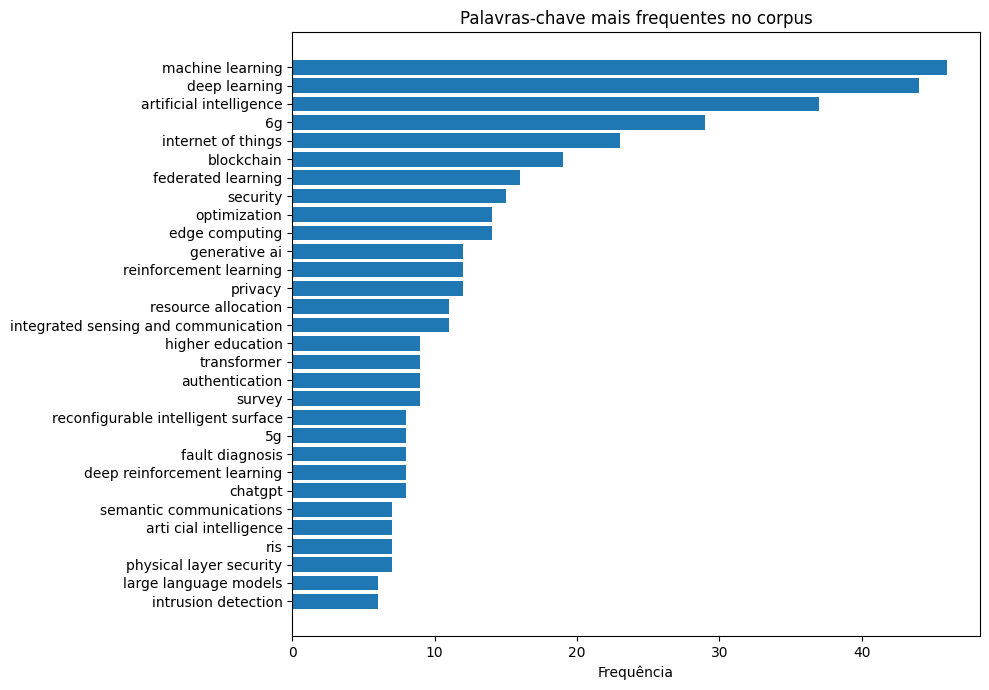

Keywords suspeitas restantes: 6


,arquivo,periodico,keywords
151,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,ICT Express,and ieee 802.15.7 standard
504,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,IEEE Communications Surveys and Tutorials,ieee 2030.5
528,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,IEEE Communications Surveys and Tutorials,ieee 802.11be
542,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,IEEE Communications Surveys and Tutorials,ieee 802.11bf
574,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,IEEE Communications Surveys and Tutorials,ieee 802.11ay
574,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,IEEE Communications Surveys and Tutorials,ieee 802.11be


In [ ]:
TERMOS_PUBLICADORES = {
    "ieee",
    "acm",
    "elsevier",
    "springer",
    "wiley",
    "sciencedirect"
}

FRASES_EDITORIAIS = [
    "all rights reserved",
    "personal use is permitted",
    "permission to reprint",
    "permission to republish",
    "authorized licensed use",
    "downloaded on",
    "copyright",
    "creative commons",
    "open access article",
    "text and data mining",
    "rights reservation",
    "rights for text and data mining",
    "digital object identifier",
    "pdf download",
    "total citations",
    "total downloads",
    "citation in bibtex format",
    "online am",
    "terms of use",
    "eissn"
]

MESES_INGLES = {
    "january", "february", "march", "april", "may", "june",
    "july", "august", "september", "october", "november", "december"
}

KEYWORDS_RUIDO = {
    "i.e.", "i.e", "ie", "e.g.", "eg",
    "however", "therefore", "thus", "although",
    "and", "or", "but",
    "ieee", "acm", "elsevier", "springer", "wiley", "sciencedirect",
    "article", "research article", "review article"
}

MAPA_KEYWORDS = {
    "ai": "artificial intelligence",
    "artificial intelligence ai": "artificial intelligence",
    "ml": "machine learning",
    "machine learning ml": "machine learning",
    "dl": "deep learning",
    "deep learning dl": "deep learning",
    "nlp": "natural language processing",
    "natural language processing nlp": "natural language processing",
    "iot": "internet of things",
    "internet of things iot": "internet of things"
}

PERIODICOS_RUIDO = {
    str(x).lower().strip()
    for x in df[COLUNA_PERIODICO].dropna().unique()
}

def cortar_referencias(texto):
    texto = str(texto)
    candidatos = list(
        re.finditer(
            r"(?im)^\s*(?:\d+\s*[.]?\s*)?(references|bibliography)\s*$",
            texto
        )
    )

    if candidatos:
        candidatos_validos = [
            m for m in candidatos
            if m.start() > len(texto) * 0.30
        ]

        if candidatos_validos:
            texto = texto[:candidatos_validos[0].start()]

    return texto

def remover_ruido_editorial(texto):
    texto = cortar_referencias(texto)
    texto = str(texto).replace("\u00ad", "")
    linhas_limpas = []

    for linha in texto.splitlines():
        linha = re.sub(r"\s+", " ", linha).strip()

        if not linha:
            continue

        linha_lower = linha.lower()

        if any(frase in linha_lower for frase in FRASES_EDITORIAIS):
            continue

        if any(periodico in linha_lower for periodico in PERIODICOS_RUIDO):
            if len(linha) <= 300:
                continue

        if re.search(r"\b(?:issn|eissn|isbn)\b", linha_lower):
            continue

        if re.search(r"\bdoi\s*[:/]", linha_lower):
            continue

        if re.search(r"\b(?:received|revised|accepted|published)\b.{0,150}\b20\d{2}\b", linha_lower):
            continue

        if re.search(r"\bvol(?:ume)?\.?\s*\d+\b", linha_lower) and re.search(r"\b(?:no|number|issue)\.?\s*\d+\b", linha_lower):
            continue

        if len(linha) <= 220 and re.search(r"\b(?:vol(?:ume)?|no|number|issue)\.?\s*\d+\b", linha_lower):
            continue

        linhas_limpas.append(linha)

    texto = " ".join(linhas_limpas)

    for periodico in sorted(PERIODICOS_RUIDO, key=len, reverse=True):
        texto = re.sub(rf"(?i)\b{re.escape(periodico)}\b", " ", texto)

    texto = re.sub(r"(?i)\bvol(?:ume)?\.?\s*\d+[a-z]?\b", " ", texto)
    texto = re.sub(r"(?i)\b(?:no|number|issue)\.?\s*\d+[a-z]?\b", " ", texto)
    texto = re.sub(r"(?i)\b(?:pp?|pages?)\.?\s*\d+(?:\s*[-–]\s*\d+)?\b", " ", texto)
    texto = re.sub(r"(?i)\b(?:issn|eissn|isbn)\s*[:#]?\s*[\dXx-]+\b", " ", texto)
    texto = re.sub(r"(?i)\bdoi\s*:\s*\S+", " ", texto)
    texto = re.sub(r"(?i)https?://(?:dx\.)?doi\.org/\S+", " ", texto)
    texto = re.sub(r"(?i)\bdoi\.org/\S+", " ", texto)
    texto = re.sub(r"(?i)\bi\s*\.\s*e\s*\.", " ", texto)
    texto = re.sub(r"(?i)\be\s*\.\s*g\s*\.", " ", texto)

    for frase in FRASES_EDITORIAIS:
        texto = re.sub(re.escape(frase), " ", texto, flags=re.I)

    for termo in TERMOS_PUBLICADORES:
        texto = re.sub(rf"(?i)\b{re.escape(termo)}\b", " ", texto)

    texto = re.sub(r"\[\s*\d+(?:\s*[,;–-]\s*\d+)*\s*\]", " ", texto)
    texto = re.sub(r"\(\s*\d+(?:\s*[,;–-]\s*\d+)*\s*\)", " ", texto)
    texto = re.sub(r"(?<![A-Za-z])\d+(?:\.\d+)?(?![A-Za-z])", " ", texto)
    texto = re.sub(r"\s+", " ", texto).strip()

    return texto

def normalizar_keyword(valor):
    valor = str(valor).lower()
    valor = valor.replace("–", "-").replace("—", "-")
    valor = re.sub(r"\[\s*\d+(?:\s*[,;–-]\s*\d+)*\s*\]", " ", valor)
    valor = re.sub(r"\(\s*\d+(?:\s*[,;–-]\s*\d+)*\s*\)", " ", valor)
    valor = re.sub(r"\(([a-z][a-z0-9+-]{1,8})\)\s*$", "", valor)
    valor = re.sub(r"^\s*\d+\s*[.)\]:-]\s*", "", valor)
    valor = re.sub(r"[^a-z0-9+#.\-\s]", " ", valor)
    valor = re.sub(r"\s+", " ", valor).strip()
    valor = valor.strip(" [](){}.,:;|-")

    chave = re.sub(r"[^a-z0-9]+", " ", valor).strip()

    return MAPA_KEYWORDS.get(chave, valor)

def keyword_eh_valida(keyword):
    if not keyword:
        return False

    keyword_lower = keyword.lower().strip()

    if keyword_lower in KEYWORDS_RUIDO:
        return False

    if keyword_lower in PERIODICOS_RUIDO:
        return False

    if any(periodico in keyword_lower for periodico in PERIODICOS_RUIDO):
        return False

    if re.fullmatch(r"\[?\s*\d+(?:\s*[,;–-]\s*\d+)*\s*\]?", keyword_lower):
        return False

    if re.fullmatch(r"\(?\s*\d+(?:\s*[,;–-]\s*\d+)*\s*\)?", keyword_lower):
        return False

    if re.fullmatch(r"\d+(?:\.\d+)?", keyword_lower):
        return False

    if re.fullmatch(r"(?:vol(?:ume)?|no|number|issue)\.?\s*\d+[a-z]?", keyword_lower):
        return False

    if re.search(r"\b(?:vol(?:ume)?|no|number|issue)\.?\s*\d+\b", keyword_lower):
        return False

    if re.search(r"\b(?:doi|issn|eissn|isbn)\b", keyword_lower):
        return False

    if "http" in keyword_lower or "doi.org" in keyword_lower:
        return False

    if any(frase in keyword_lower for frase in FRASES_EDITORIAIS):
        return False

    if re.search(r"\b(?:pages?|copyright|rights reserved|bibtex|citations?|downloads?)\b", keyword_lower):
        return False

    if re.search(r"\[\s*\d+", keyword_lower):
        return False

    if re.search(r"^\d+\s*pages?$", keyword_lower):
        return False

    if re.search(r"^article\s*\(", keyword_lower):
        return False

    if any(mes in keyword_lower for mes in MESES_INGLES) and "article" in keyword_lower:
        return False

    if len(keyword_lower) < 2 or len(keyword_lower) > 80:
        return False

    n_palavras = len(keyword_lower.split())

    if n_palavras > 7:
        return False

    if n_palavras >= 5 and re.search(r"\b(?:is|are|was|were|has|have|introduced|proposed|presents?)\b", keyword_lower):
        return False

    return True

def extrair_keywords(texto):
    texto = str(texto).replace("\r\n", "\n").replace("\r", "\n").replace("\u00ad", "")
    trecho = texto[:35000]

    candidatos = [
        (
            "acm",
            re.search(
                r"(?is)Additional\s*Key\s*Words?\s*and\s*Phrases\s*[:：]?\s*",
                trecho
            )
        ),
        (
            "proceedings",
            re.search(
                r"(?is)KEYWORDS?\s*\|\s*",
                trecho
            )
        ),
        (
            "ieee",
            re.search(
                r"(?is)Index\s*Terms?\s*(?:—|–|-)+\s*",
                trecho
            )
        ),
        (
            "index_colon",
            re.search(
                r"(?is)Index\s*Terms?\s*[:：]\s*",
                trecho
            )
        ),
        (
            "colon",
            re.search(
                r"(?is)Keywords?\s*[:：]\s*",
                trecho
            )
        ),
        (
            "springer",
            re.search(
                r"(?is)Keywords?\s+(?=[^\n]{0,350}·)",
                trecho
            )
        )
    ]

    estilo = None
    marcador = None

    for nome, match in candidatos:
        if match:
            estilo = nome
            marcador = match
            break

    if not marcador:
        return []

    janela = trecho[marcador.end():marcador.end() + 1400]

    if estilo == "acm":

        bloco = re.split(
            r"(?is)"
            r"ACM\s*Reference\s*Format|"
            r"Authors?['’]?\s*Contact\s*Information|"
            r"1\s+INTRODUCTION",
            janela,
            maxsplit=1
        )[0]

        bloco = re.sub(r"-\s*\n\s*", "-", bloco)
        bloco = re.sub(r"\s+", " ", bloco).strip()

        itens = re.split(
            r"\s*[,;•·|]\s*",
            bloco
        )

    elif estilo in {"proceedings", "ieee"}:

        bloco = re.split(
            r"(?is)(?:"
            r"\bI\s*\.\s*I\s*N\s*T\s*R\s*O\s*D\s*U\s*C\s*T\s*I\s*O\s*N\b|"
            r"\bI\s*\.\s*INTRODUCTION\b|"
            r"\bN\s*O\s*M\s*E\s*N\s*C\s*L\s*A\s*T\s*U\s*R\s*E\b|"
            r"\bACRONYMS?\b|"
            r"\b(?:Manuscript\s+)?Received\b"
            r")",
            janela,
            maxsplit=1
        )[0]

        bloco = re.sub(r"-\s*\n\s*", "-", bloco)
        bloco = re.sub(r"\s+", " ", bloco).strip()

        itens = re.split(
            r"\s*[;,]\s*",
            bloco
        )

    elif estilo == "springer":

        bloco = re.split(
            r"(?is)(?:"
            r"\b\d+\s+Introduction\b|"
            r"\bReceived\s*:|"
            r"\bIntroduction\b"
            r")",
            janela,
            maxsplit=1
        )[0]

        bloco = re.sub(r"-\s*\n\s*", "-", bloco)
        bloco = re.sub(r"\s+", " ", bloco).strip()

        itens = re.split(
            r"\s*·\s*",
            bloco
        )

    else:

        bloco = re.split(
            r"(?is)(?:"
            r"A\s*B\s*S\s*T\s*R\s*A\s*C\s*T|"
            r"\bABSTRACT\b|"
            r"\b\d+\s*[\.\-]?\s*Introduction\b|"
            r"\bI\s*\.\s*I\s*N\s*T\s*R\s*O\s*D\s*U\s*C\s*T\s*I\s*O\s*N\b|"
            r"\bReceived\s*:|"
            r"\bIntroduction\b"
            r")",
            janela,
            maxsplit=1
        )[0]

        if ";" in bloco:

            bloco = re.sub(r"-\s*\n\s*", "-", bloco)
            bloco = re.sub(r"\s+", " ", bloco).strip()

            itens = re.split(
                r"\s*;\s*",
                bloco
            )

        elif "·" in bloco:

            bloco = re.sub(r"-\s*\n\s*", "-", bloco)
            bloco = re.sub(r"\s+", " ", bloco).strip()

            itens = re.split(
                r"\s*·\s*",
                bloco
            )

        elif "," in bloco and bloco.count("\n") <= 2:

            bloco = re.sub(r"-\s*\n\s*", "-", bloco)
            bloco = re.sub(r"\s+", " ", bloco).strip()

            itens = re.split(
                r"\s*,\s*",
                bloco
            )

        else:

            linhas = [
                re.sub(r"\s+", " ", linha).strip()
                for linha in bloco.splitlines()
                if linha.strip()
            ]

            itens = []

            for linha in linhas[:12]:

                if len(linha.split()) > 10 or len(linha) > 100:
                    break

                if linha.startswith("(") and itens:
                    itens[-1] += " " + linha
                else:
                    itens.append(linha)

    saida = []

    for item in itens:
        item = normalizar_keyword(item)

        if keyword_eh_valida(item):
            saida.append(item)

    return list(dict.fromkeys(saida))

df["keywords"] = df[COLUNA_TEXTO].map(extrair_keywords)
df["n_keywords"] = df["keywords"].map(len)

keywords_df = (
    df[[COLUNA_ID, COLUNA_PERIODICO, "keywords"]]
    .explode("keywords")
    .dropna(subset=["keywords"])
)

keywords_df = keywords_df[keywords_df["keywords"].astype(str).str.strip().ne("")].copy()

print("Artigos com keywords identificadas:", int((df["n_keywords"] > 0).sum()))
print("Cobertura:", round(100 * (df["n_keywords"] > 0).mean(), 2), "%")

top_keywords = (
    keywords_df["keywords"]
    .value_counts()
    .head(TOP_KEYWORDS)
    .rename_axis("keyword")
    .reset_index(name="frequencia")
)

display(top_keywords)

plt.figure(figsize=(10, 7))
plt.barh(top_keywords["keyword"][::-1], top_keywords["frequencia"][::-1])
plt.xlabel("Frequência")
plt.title("Palavras-chave mais frequentes no corpus")
plt.tight_layout()
plt.show()

padroes_suspeitos = (
    r"^\[?\d+\]?$|"
    r"\bvol\.?\s*\d+|"
    r"\bno\.?\s*\d+|"
    r"\bissue\s*\d+|"
    r"\bieee\b|"
    r"\bacm\b|"
    r"\bdoi\b|"
    r"\bcopyright\b|"
    r"\bpages?\b|"
    r"\barticle\s*\("
)

suspeitas = keywords_df[
    keywords_df["keywords"].str.contains(
        padroes_suspeitos,
        case=False,
        regex=True,
        na=False
    )
]

print("Keywords suspeitas restantes:", len(suspeitas))
display(suspeitas.head(30))

In [ ]:
keywords_periodico = (
    keywords_df
    .groupby([COLUNA_PERIODICO, "keywords"])
    .size()
    .reset_index(name="frequencia")
)

top_keywords_periodico = (
    keywords_periodico
    .sort_values([COLUNA_PERIODICO, "frequencia"], ascending=[True, False])
    .groupby(COLUNA_PERIODICO)
    .head(TOP_KEYWORDS_PERIODICO)
    .sort_values("frequencia", ascending=False)
    .reset_index(drop=True)
)

display(top_keywords_periodico)

presenca = (
    keywords_periodico
    .assign(presente=1)
    .pivot_table(
        index="keywords",
        columns=COLUNA_PERIODICO,
        values="presente",
        aggfunc="max",
        fill_value=0
    )
)

frequencia_total = keywords_periodico.groupby("keywords")["frequencia"].sum()

resumo_comuns = pd.DataFrame({
    "n_periodicos": presenca.sum(axis=1),
    "frequencia_total": frequencia_total
}).sort_values(
    ["frequencia_total", "n_periodicos"],
    ascending=[False, False]
)

display(resumo_comuns.head(50))

,periodico,keywords,frequencia
0,IEEE Communications Surveys and Tutorials,6g,14
1,Education and Information Technologies,artificial intelligence,14
2,Computer Science Review,deep learning,13
3,ACM Computing Surveys,deep learning,12
4,Computer Science Review,machine learning,11
...,...,...,...
155,Information Sciences,android malware,1
156,Information Sciences,adaptive acceleration,1
157,Information Sciences,adaptive entropy,1
158,Information Sciences,adaptive nesterov momentum algorithm,1


,n_periodicos,frequencia_total
keywords,,
machine learning,7,46
deep learning,6,44
artificial intelligence,6,37
6g,4,29
internet of things,5,23
blockchain,6,19
federated learning,6,16
security,4,15
optimization,7,14


,ACM Computing Surveys,Computer Science Review,Education and Information Technologies,ICT Express,IEEE Communications Surveys and Tutorials,ISA Transactions,Information Sciences,Proceedings of the IEEE
ACM Computing Surveys,1.000,0.124,0.01,0.087,0.124,0.010,0.020,0.099
Computer Science Review,0.124,1.000,0.01,0.149,0.163,0.020,0.020,0.087
Education and Information Technologies,0.010,0.010,1.00,0.010,0.010,0.000,0.000,0.010
ICT Express,0.087,0.149,0.01,1.000,0.163,0.020,0.042,0.099
IEEE Communications Surveys and Tutorials,0.124,0.163,0.01,0.163,1.000,0.020,0.042,0.149
ISA Transactions,0.010,0.020,0.00,0.020,0.020,1.000,0.031,0.000
Information Sciences,0.020,0.020,0.00,0.042,0.042,0.031,1.000,0.010
Proceedings of the IEEE,0.099,0.087,0.01,0.099,0.149,0.000,0.010,1.000


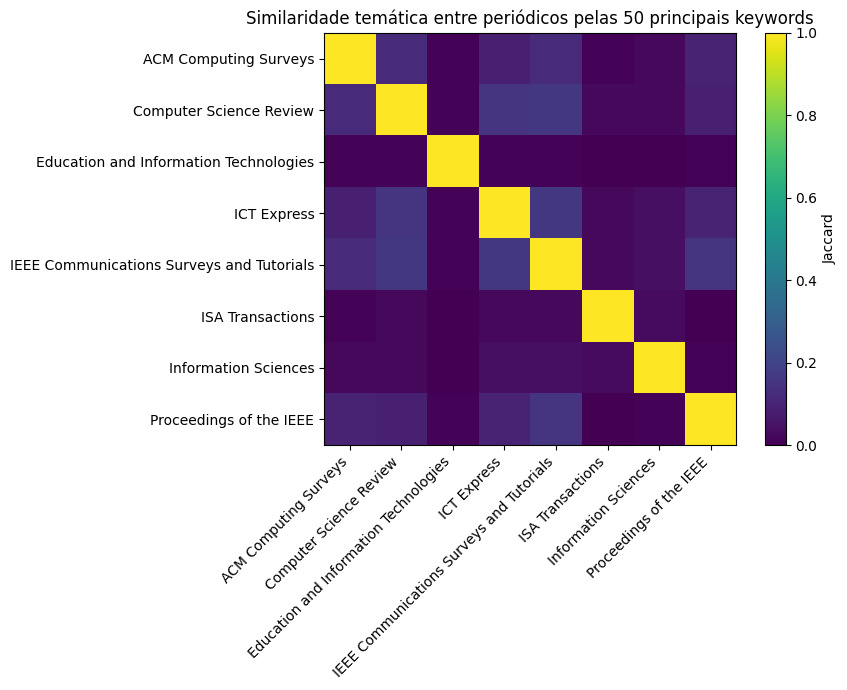

In [ ]:
top_sets = {}

for periodico, grupo in keywords_periodico.groupby(COLUNA_PERIODICO):
    top_sets[periodico] = set(
        grupo.sort_values("frequencia", ascending=False)
        .head(50)["keywords"]
    )

periodicos = sorted(top_sets)
jaccard_keywords = pd.DataFrame(index=periodicos, columns=periodicos, dtype=float)

for p1 in periodicos:
    for p2 in periodicos:
        uniao = top_sets[p1] | top_sets[p2]
        intersecao = top_sets[p1] & top_sets[p2]
        jaccard_keywords.loc[p1, p2] = len(intersecao) / len(uniao) if uniao else np.nan

display(jaccard_keywords.round(3))

plt.figure(figsize=(9, 7))
plt.imshow(jaccard_keywords.values, vmin=0, vmax=1)
plt.xticks(range(len(periodicos)), periodicos, rotation=45, ha="right")
plt.yticks(range(len(periodicos)), periodicos)
plt.colorbar(label="Jaccard")
plt.title("Similaridade temática entre periódicos pelas 50 principais keywords")
plt.tight_layout()
plt.show()

In [ ]:
artigos_sem_keywords = df[df["n_keywords"] == 0].copy()

print("Artigos sem keywords identificadas:", len(artigos_sem_keywords))

display(
    artigos_sem_keywords[
        [COLUNA_ID, COLUNA_PERIODICO]
    ].reset_index(drop=True)
)

Artigos sem keywords identificadas: 19


,arquivo,periodico
0,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,Education and Information Technologies
1,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,Education and Information Technologies
2,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,Education and Information Technologies
3,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,Education and Information Technologies
4,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,ISA Transactions
5,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,Computer Science Review
6,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,Computer Science Review
7,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,Proceedings of the IEEE
8,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,Proceedings of the IEEE
9,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,Proceedings of the IEEE


### 5.1 Controle temático por resumo

As palavras-chave são escolhas dos autores e, por isso, não representam necessariamente todos os assuntos abordados no artigo. Como controle adicional, esta etapa extrai o resumo e verifica a presença de famílias temáticas frequentes. Essa análise é apenas exploratória e **não entra na clusterização**.

In [ ]:
def extrair_resumo(texto):
    texto = str(texto).replace("\r\n", "\n").replace("\r", "\n")
    trecho = texto[:30000]

    marcador = re.search(r"(?is)\babstract\b\s*[:—–-]?\s*", trecho)

    if not marcador:
        return ""

    janela = trecho[marcador.end():marcador.end() + 6000]

    fim = re.search(
        r"(?is)\b(?:keywords?|key\s+words|index\s+terms|ccs concepts|"
        r"(?:1|i)\s*[.]?\s*introduction)\b",
        janela
    )

    if fim:
        janela = janela[:fim.start()]

    janela = re.sub(r"\s+", " ", janela).strip()

    if len(janela.split()) < 30:
        return ""

    return janela

def extrair_introducao(texto):
    texto = str(texto).replace("\r\n", "\n").replace("\r", "\n")
    trecho = texto[:80000]

    marcador = re.search(
        r"(?im)^\s*(?:1|i)?\s*[.]?\s*introduction\s*$",
        trecho
    )

    if not marcador:
        marcador = re.search(r"(?i)\b1\s*[.]?\s*introduction\b", trecho)

    if not marcador:
        return ""

    janela = trecho[marcador.end():marcador.end() + 20000]

    fim = re.search(
        r"(?im)^\s*(?:2|ii)\s*[.]?\s*(?:background|related work|literature review|"
        r"method|methods|methodology|materials and methods)\b",
        janela
    )

    if fim:
        janela = janela[:fim.start()]

    return re.sub(r"\s+", " ", janela).strip()

df["resumo_extraido"] = df[COLUNA_TEXTO].map(extrair_resumo)
df["introducao_extraida"] = df[COLUNA_TEXTO].map(extrair_introducao)

print("Resumos extraídos:", int(df["resumo_extraido"].str.len().gt(0).sum()))
print("Introduções extraídas:", int(df["introducao_extraida"].str.len().gt(0).sum()))

TEMAS_CONTROLE = {
    "Inteligência Artificial / Machine Learning": [
        r"\bartificial intelligence\b",
        r"\bmachine learning\b",
        r"\bdeep learning\b",
        r"\bneural networks?\b",
        r"\bgenerative ai\b",
        r"\blarge language models?\b",
        r"\btransformers?\b"
    ],
    "Processamento de Linguagem Natural": [
        r"\bnatural language processing\b",
        r"\bnlp\b",
        r"\blanguage models?\b"
    ],
    "Visão Computacional": [
        r"\bcomputer vision\b",
        r"\bimage classification\b",
        r"\bobject detection\b",
        r"\bimage segmentation\b"
    ],
    "Engenharia de Software": [
        r"\bsoftware engineering\b",
        r"\bsoftware development\b",
        r"\bsoftware testing\b"
    ],
    "Redes e Comunicações": [
        r"\bwireless\b",
        r"\b5g\b",
        r"\b6g\b",
        r"\bcommunication networks?\b",
        r"\binternet of things\b",
        r"\biot\b"
    ],
    "Computação e Educação": [
        r"\bcomputing education\b",
        r"\bcomputer science education\b",
        r"\bhigher education\b",
        r"\bcomputational thinking\b"
    ]
}

def identificar_temas_resumo(texto):
    texto = str(texto).lower()
    temas = []

    for tema, padroes in TEMAS_CONTROLE.items():
        if any(re.search(padrao, texto) for padrao in padroes):
            temas.append(tema)

    return temas

df["temas_resumo"] = df["resumo_extraido"].map(identificar_temas_resumo)

temas_resumo_df = (
    df[[COLUNA_ID, COLUNA_PERIODICO, "temas_resumo"]]
    .explode("temas_resumo")
    .dropna(subset=["temas_resumo"])
)

frequencia_temas_resumo = (
    temas_resumo_df["temas_resumo"]
    .value_counts()
    .rename_axis("tema")
    .reset_index(name="n_artigos")
)

frequencia_temas_resumo["percentual_corpus"] = (
    100 * frequencia_temas_resumo["n_artigos"] / len(df)
)

display(frequencia_temas_resumo)

Resumos extraídos: 348
Introduções extraídas: 541


,tema,n_artigos,percentual_corpus
0,Inteligência Artificial / Machine Learning,115,14.465409
1,Redes e Comunicações,112,14.088050
2,Computação e Educação,21,2.641509
3,Processamento de Linguagem Natural,17,2.138365
4,Engenharia de Software,2,0.251572
5,Visão Computacional,2,0.251572


## 6. Pré-processamento textual

O pré-processamento foi ajustado para reduzir a influência de informações editoriais presentes na extração dos PDFs. Antes da tokenização e das representações vetoriais, são removidos cabeçalhos e rodapés recorrentes, informações de volume e edição, DOI, ISSN/ISBN, avisos de copyright e licença, datas editoriais, nomes de publicadores, abreviações como `i.e.` e `e.g.`, citações numéricas e números isolados.

Termos alfanuméricos que representam conceitos científicos, como `5G` e `6G`, são preservados. Para BoW e TF-IDF, também são aplicadas tokenização, remoção de stopwords e normalização morfológica. Para embeddings contextuais, o texto conserva sua estrutura natural após a remoção dos ruídos editoriais.

In [ ]:
STOPWORDS_EN = set(stopwords.words("english"))

def limpar_texto_base(texto):
    texto = remover_ruido_editorial(texto)
    texto = re.sub(r"https?://\S+|www\.\S+", " ", texto)
    texto = re.sub(r"\bdoi\s*:\s*\S+", " ", texto, flags=re.I)
    texto = re.sub(r"[\t\r\n]+", " ", texto)
    texto = re.sub(r"\s+", " ", texto)
    return texto.strip()

class AcademicTextPreprocessor(BaseEstimator, TransformerMixin):
    def __init__(self, normalization="lemma"):
        self.normalization = normalization

    def fit(self, X, y=None):
        self.lemmatizer_ = WordNetLemmatizer()
        self.stemmer_ = PorterStemmer()
        return self

    def transform(self, X):
        return np.array([self._processar(texto) for texto in X], dtype=object)

    def _processar(self, texto):
        texto = limpar_texto_base(texto).lower()
        tokens = word_tokenize(texto)

        tokens = [
            token
            for token in tokens
            if re.fullmatch(r"[a-z]+|[a-z]*\d+[a-z]+|[a-z]+\d+[a-z]*", token)
            and len(token) >= 3
            and token not in STOPWORDS_EN
        ]

        if self.normalization == "lemma":
            tokens = [
                self.lemmatizer_.lemmatize(token)
                if token.isalpha()
                else token
                for token in tokens
            ]
        elif self.normalization == "stem":
            tokens = [
                self.stemmer_.stem(token)
                if token.isalpha()
                else token
                for token in tokens
            ]

        return " ".join(tokens)

class DenseTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        if sparse.issparse(X):
            return X.toarray()
        return np.asarray(X)

### 6.1 Diagnóstico da limpeza editorial

Esta verificação contabiliza ocorrências de alguns ruídos antes e depois da função de limpeza. O esperado é que as ocorrências editoriais caiam para zero ou para valores residuais muito baixos. Também é apresentada uma amostra do texto antes e depois do tratamento.

In [ ]:
PADROES_DIAGNOSTICO = {
    "volume": r"(?i)\bvol(?:ume)?\.?\s*\d+\b",
    "numero_edicao": r"(?i)\b(?:no|number|issue)\.?\s*\d+\b",
    "i.e.": r"(?i)\bi\s*\.\s*e\s*\.",
    "e.g.": r"(?i)\be\s*\.\s*g\s*\.",
    "IEEE": r"(?i)\bieee\b",
    "DOI": r"(?i)\bdoi\b",
    "copyright": r"(?i)\bcopyright\b",
    "marcador_citacao": r"\[\s*\d+(?:\s*[,;–-]\s*\d+)*\s*\]",
    "numero_isolado": r"(?<![A-Za-z])\d+(?:\.\d+)?(?![A-Za-z])",
    "pdf_download": r"(?i)\bpdf download\b",
    "total_citations": r"(?i)\btotal citations\b",
    "bibtex": r"(?i)\bbibtex\b"
}

def contar_padrao_serie(serie, padrao):
    return int(sum(len(re.findall(padrao, str(texto))) for texto in serie))

amostra_depois = df[COLUNA_TEXTO].map(limpar_texto_base)

diagnostico_ruido = pd.DataFrame([
    {
        "ruido": nome,
        "antes": contar_padrao_serie(df[COLUNA_TEXTO], padrao),
        "depois": contar_padrao_serie(amostra_depois, padrao)
    }
    for nome, padrao in PADROES_DIAGNOSTICO.items()
])

display(diagnostico_ruido)

indice_amostra = 0

print("ANTES:")
print(df.loc[indice_amostra, COLUNA_TEXTO][:1500])

print("\nDEPOIS:")
print(amostra_depois.iloc[indice_amostra][:1500])

,ruido,antes,depois
0,volume,30296,0
1,numero_edicao,26887,0
2,i.e.,4959,0
3,e.g.,7050,0
4,IEEE,45483,1
5,DOI,16465,51
6,copyright,204,0
7,marcador_citacao,206150,0
8,numero_isolado,1160471,432
9,pdf_download,100,0


ANTES:
.
.
Latest updates: hps://dl.acm.org/doi/10.1145/3664614
.
.
SURVEY
A Review of Explainable Fashion Compatibility
Modeling Methods
KAROLINA SELWON, Gdańsk University of Technology, Gdansk, Poland
.
JULIAN SZYMAŃSKI, Gdańsk University of Technology, Gdansk, Poland
.
.
.
Open Access Support provided by:
.
Gdańsk University of Technology
.
PDF Download
3664614.pdf
08 February 2026
Total Citations: 3
Total Downloads: 794
.
.Published: 28 June 2024
Online AM: 11 May 2024
Accepted: 23 April 2024
Revised: 28 October 2023
Received: 12 October 2022
.
.
Citation in BibTeX format
.
.
ACM Computing Surveys, Volume 56, Issue 11 (November 2024)
hps://doi.org/10.1145/3664614
EISSN: 1557-7341
.
A Review of Explainable Fashion Compatibility Modeling
Methods
KAROLINASELWON ,GdańskUniversityofTechnologyFacultyofElectronicsTelecommunicationsand
Informatics,Gdansk, Poland
JULIANSZYMAŃSKI ,GdańskUniversityofTechnologyFacultyofElectronicsTelecommunicationsand
Informatics,Gdansk, Poland
The paper rev

### 6.2 Caracterização estrutural dos artigos

Esta etapa extrai indicadores que descrevem **como o artigo é organizado**, independentemente do tema estudado. São consideradas extensão textual, páginas, figuras, tabelas, equações, citações, referências, densidade numérica e presença de seções típicas.

As quantidades de figuras, tabelas e equações são estimadas a partir de identificadores encontrados no texto extraído. Quando o PDF original está acessível, também é calculada a proporção aproximada da área ocupada por blocos de imagem rasterizada. Como gráficos vetoriais e algumas tabelas podem não ser reconhecidos como imagens, essa medida é utilizada apenas como indicador complementar.

Esses atributos formam a componente estrutural da representação híbrida. As categorias metodológicas específicas são mantidas fora da clusterização e utilizadas apenas na interpretação posterior dos grupos.

In [ ]:
def localizar_pdf(caminho):
    caminho = Path(str(caminho))

    if caminho.exists():
        return caminho

    partes = Path(str(caminho).replace("\\", "/")).parts
    indices = [i for i, parte in enumerate(partes) if parte == PASTA_RAIZ_PERIODICOS]

    if indices:
        relativo = partes[indices[-1] + 1:]
        candidato = Path(CAMINHO_BASE_PDFS).joinpath(*relativo)

        if candidato.exists():
            return candidato

    return None

def contar_identificadores(texto, padrao):
    encontrados = re.findall(padrao, str(texto), flags=re.I)
    return len(set(str(x).lower() for x in encontrados))

def extrair_bloco_referencias(texto):
    texto = str(texto)
    candidatos = list(
        re.finditer(
            r"(?im)^\s*(?:\d+\s*[.]?\s*)?(references|bibliography)\s*$",
            texto
        )
    )

    candidatos = [m for m in candidatos if m.start() > len(texto) * 0.30]

    if not candidatos:
        return ""

    return texto[candidatos[0].end():]

def estimar_numero_referencias(texto):
    bloco = extrair_bloco_referencias(texto)

    if not bloco:
        return 0

    numeradas_colchetes = re.findall(r"(?m)^\s*\[\s*(\d+)\s*\]", bloco)
    numeradas_ponto = re.findall(r"(?m)^\s*(\d+)\s*[.)]\s+", bloco)

    if numeradas_colchetes or numeradas_ponto:
        valores = [int(x) for x in numeradas_colchetes + numeradas_ponto]
        return max(valores)

    anos = re.findall(r"\b(?:19|20)\d{2}[a-z]?\b", bloco)
    return len(anos)

def extrair_metricas_pdf(caminho):
    saida = {
        "n_paginas": np.nan,
        "n_blocos_imagem_pdf": np.nan,
        "proporcao_area_imagens_pdf": np.nan
    }

    if not EXTRAIR_METRICAS_VISUAIS_PDF:
        return saida

    caminho_pdf = localizar_pdf(caminho)

    if caminho_pdf is None:
        return saida

    try:
        documento = fitz.open(str(caminho_pdf))
        area_total = 0.0
        area_imagens = 0.0
        n_blocos = 0

        for pagina in documento:
            area_pagina = float(pagina.rect.width * pagina.rect.height)
            area_total += area_pagina
            dados = pagina.get_text("dict")

            for bloco in dados.get("blocks", []):
                if bloco.get("type") != 1:
                    continue

                x0, y0, x1, y1 = bloco.get("bbox", (0, 0, 0, 0))
                area = max(0.0, float(x1 - x0)) * max(0.0, float(y1 - y0))

                if area_pagina > 0 and area / area_pagina >= MIN_AREA_RELATIVA_BLOCO_IMAGEM:
                    area_imagens += area
                    n_blocos += 1

        saida["n_paginas"] = len(documento)
        saida["n_blocos_imagem_pdf"] = n_blocos
        saida["proporcao_area_imagens_pdf"] = area_imagens / area_total if area_total > 0 else np.nan
        documento.close()

    except Exception:
        pass

    return saida

def extrair_indicadores_estruturais(texto, caminho):
    texto = str(texto)
    corpo = cortar_referencias(texto)
    palavras = re.findall(r"\b[\w'-]+\b", corpo, flags=re.UNICODE)
    n_palavras = len(palavras)

    n_figuras = contar_identificadores(
        corpo,
        r"\b(?:fig(?:ure)?\.?)\s*(\d+[a-z]?)\b"
    )
    n_tabelas = contar_identificadores(
        corpo,
        r"\btable\s*(\d+[a-z]?)\b"
    )
    n_equacoes = contar_identificadores(
        corpo,
        r"\b(?:eq(?:uation)?\.?)\s*\(?(\d+[a-z]?)\)?"
    )

    identificadores_graficos = re.findall(
        r"(?im)^\s*(?:fig(?:ure)?\.?)\s*(\d+[a-z]?)\b.{0,250}\b(?:graph|plot|chart|curve|histogram|scatter|boxplot)\b",
        corpo
    )
    n_graficos_estimados = len(set(x.lower() for x in identificadores_graficos))

    citacoes_numericas = len(
        re.findall(
            r"\[\s*\d+(?:\s*[,;–-]\s*\d+)*\s*\]",
            corpo
        )
    )
    citacoes_autor_ano = len(
        re.findall(
            r"\([A-Z][A-Za-zÀ-ÿ'’-]+(?:\s+et\s+al\.)?(?:,\s*|\s+)(?:19|20)\d{2}[a-z]?\)",
            corpo
        )
    )

    numeros = len(
        re.findall(
            r"(?<![A-Za-z])[-+]?\d+(?:[.,]\d+)?%?(?![A-Za-z])",
            corpo
        )
    )

    padroes_secoes = {
        "tem_introducao": r"(?im)^\s*(?:\d+(?:\.\d+)*\s*)?introduction\b",
        "tem_metodos": r"(?im)^\s*(?:\d+(?:\.\d+)*\s*)?(?:materials?\s+and\s+methods?|methods?|methodology|research\s+method(?:ology)?)\b",
        "tem_resultados": r"(?im)^\s*(?:\d+(?:\.\d+)*\s*)?(?:results?|findings)\b",
        "tem_discussao": r"(?im)^\s*(?:\d+(?:\.\d+)*\s*)?discussion\b",
        "tem_conclusao": r"(?im)^\s*(?:\d+(?:\.\d+)*\s*)?(?:conclusion|conclusions|concluding\s+remarks)\b"
    }

    secoes = {
        nome: int(bool(re.search(padrao, corpo)))
        for nome, padrao in padroes_secoes.items()
    }

    n_referencias = estimar_numero_referencias(texto)
    metricas_pdf = extrair_metricas_pdf(caminho)
    n_paginas = metricas_pdf["n_paginas"]
    denominador = max(n_palavras, 1)

    elementos_visuais = n_figuras + n_tabelas

    saida = {
        "n_palavras": n_palavras,
        "log_n_palavras": np.log1p(n_palavras),
        "n_paginas": n_paginas,
        "palavras_por_pagina": n_palavras / n_paginas if pd.notna(n_paginas) and n_paginas > 0 else np.nan,
        "n_figuras": n_figuras,
        "n_graficos_estimados": n_graficos_estimados,
        "n_tabelas": n_tabelas,
        "n_equacoes": n_equacoes,
        "n_referencias": n_referencias,
        "citacoes_por_1000_palavras": 1000 * (citacoes_numericas + citacoes_autor_ano) / denominador,
        "numeros_por_1000_palavras": 1000 * numeros / denominador,
        "figuras_por_1000_palavras": 1000 * n_figuras / denominador,
        "graficos_por_1000_palavras": 1000 * n_graficos_estimados / denominador,
        "tabelas_por_1000_palavras": 1000 * n_tabelas / denominador,
        "equacoes_por_1000_palavras": 1000 * n_equacoes / denominador,
        "elementos_visuais_por_pagina": elementos_visuais / n_paginas if pd.notna(n_paginas) and n_paginas > 0 else np.nan,
        "referencias_por_1000_palavras": 1000 * n_referencias / denominador,
        **secoes,
        **metricas_pdf
    }

    saida["n_secoes_identificadas"] = sum(secoes.values())
    return saida

indicadores_estruturais = pd.DataFrame([
    extrair_indicadores_estruturais(texto, caminho)
    for texto, caminho in zip(df[COLUNA_TEXTO], df[COLUNA_ID])
])

indicadores_estruturais.index = df.index

for coluna in indicadores_estruturais.columns:
    df[coluna] = indicadores_estruturais[coluna]

COLUNAS_ESTRUTURA_CLUSTER = [
    "log_n_palavras",
    "palavras_por_pagina",
    "figuras_por_1000_palavras",
    "graficos_por_1000_palavras",
    "tabelas_por_1000_palavras",
    "equacoes_por_1000_palavras",
    "elementos_visuais_por_pagina",
    "referencias_por_1000_palavras",
    "citacoes_por_1000_palavras",
    "numeros_por_1000_palavras",
    "proporcao_area_imagens_pdf",
    "n_secoes_identificadas",
    "tem_introducao",
    "tem_metodos",
    "tem_resultados",
    "tem_discussao",
    "tem_conclusao"
]

display(
    df[
        [COLUNA_ID, COLUNA_PERIODICO]
        + [
            "n_palavras",
            "n_paginas",
            "n_figuras",
            "n_graficos_estimados",
            "n_tabelas",
            "n_equacoes",
            "n_referencias",
            "proporcao_area_imagens_pdf"
        ]
    ].head()
)

print("PDFs com métricas visuais:", int(df["n_paginas"].notna().sum()), "de", len(df))

,arquivo,periodico,n_palavras,n_paginas,n_figuras,n_graficos_estimados,n_tabelas,n_equacoes,n_referencias,proporcao_area_imagens_pdf
0,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,ACM Computing Surveys,10368,NaN,0,0,2,0,12731,NaN
1,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,ACM Computing Surveys,11436,NaN,8,0,4,0,2346,NaN
2,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,ACM Computing Surveys,13240,NaN,16,0,2,0,175,NaN
3,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,ACM Computing Surveys,14255,NaN,3,0,13,0,103159,NaN
4,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,ACM Computing Surveys,14023,NaN,7,0,7,0,2680,NaN


PDFs com métricas visuais: 0 de 795


## 7. Representações vetoriais

In [ ]:
class DocumentEmbeddingTransformer(BaseEstimator, TransformerMixin):
    def __init__(
        self,
        model_name=MODELO_EMBEDDING,
        palavras_por_chunk=PALAVRAS_POR_CHUNK,
        max_chunks=MAX_CHUNKS_EMBEDDING,
        batch_size=BATCH_SIZE_EMBEDDING
    ):
        self.model_name = model_name
        self.palavras_por_chunk = palavras_por_chunk
        self.max_chunks = max_chunks
        self.batch_size = batch_size

    def fit(self, X, y=None):
        self.model_ = SentenceTransformer(self.model_name)
        return self

    def transform(self, X):
        vetores_documentos = []

        for texto in X:
            texto = limpar_texto_base(texto)
            palavras = texto.split()

            chunks = [
                " ".join(palavras[i:i + self.palavras_por_chunk])
                for i in range(0, len(palavras), self.palavras_por_chunk)
                if palavras[i:i + self.palavras_por_chunk]
            ]

            if not chunks:
                chunks = [""]

            if len(chunks) > self.max_chunks:
                indices = np.linspace(
                    0,
                    len(chunks) - 1,
                    self.max_chunks
                ).round().astype(int)
                chunks = [chunks[i] for i in indices]

            vetores = self.model_.encode(
                chunks,
                batch_size=self.batch_size,
                show_progress_bar=False,
                normalize_embeddings=True
            )

            vetor = np.mean(vetores, axis=0)
            norma = np.linalg.norm(vetor)

            if norma > 0:
                vetor = vetor / norma

            vetores_documentos.append(vetor)

        return np.vstack(vetores_documentos)

def construir_representador(nome):
    if nome == "BoW":
        return Pipeline([
            ("preprocessamento", AcademicTextPreprocessor(NORMALIZACAO_LEXICAL)),
            ("representacao", CountVectorizer(
                max_features=MAX_FEATURES,
                min_df=MIN_DF,
                max_df=MAX_DF
            )),
            ("denso", DenseTransformer()),
            ("normalizacao", Normalizer(norm="l2"))
        ])

    if nome == "TF-IDF":
        return Pipeline([
            ("preprocessamento", AcademicTextPreprocessor(NORMALIZACAO_LEXICAL)),
            ("representacao", TfidfVectorizer(
                max_features=MAX_FEATURES,
                min_df=MIN_DF,
                max_df=MAX_DF,
                sublinear_tf=True,
                norm="l2"
            )),
            ("denso", DenseTransformer())
        ])

    if nome == "Embeddings":
        return Pipeline([
            ("representacao", DocumentEmbeddingTransformer())
        ])

    raise ValueError(f"Representação desconhecida: {nome}")

In [ ]:
representacoes_base = ["BoW", "TF-IDF", "Embeddings"]
representadores = {}
matrizes = {}

for nome in representacoes_base:
    print("Gerando representação:", nome)
    representador = construir_representador(nome)
    X = representador.fit_transform(df[COLUNA_TEXTO].tolist())

    representadores[nome] = representador
    matrizes[nome] = np.asarray(X)

estrutura_modelo = df[COLUNAS_ESTRUTURA_CLUSTER].copy()

for coluna in estrutura_modelo.columns:
    if estrutura_modelo[coluna].notna().any():
        estrutura_modelo[coluna] = estrutura_modelo[coluna].fillna(
            estrutura_modelo[coluna].median()
        )
    else:
        estrutura_modelo[coluna] = 0.0

scaler_estrutura = StandardScaler()
X_estrutura_padronizada = scaler_estrutura.fit_transform(estrutura_modelo)
X_estrutura = Normalizer(norm="l2").fit_transform(X_estrutura_padronizada)

matrizes["Estrutura"] = X_estrutura

X_hibrida = np.hstack([
    PESO_EMBEDDING_HIBRIDO * matrizes["Embeddings"],
    PESO_ESTRUTURA_HIBRIDO * X_estrutura
])

X_hibrida = Normalizer(norm="l2").fit_transform(X_hibrida)
matrizes["Embeddings + Estrutura"] = X_hibrida

representacoes = list(matrizes.keys())

for nome in representacoes:
    print(nome, matrizes[nome].shape)

Gerando representação: BoW
Gerando representação: TF-IDF
Gerando representação: Embeddings


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

BoW (795, 6000)
TF-IDF (795, 6000)
Embeddings (795, 384)
Estrutura (795, 17)
Embeddings + Estrutura (795, 401)


### 7.1 Indicadores exploratórios de perfil metodológico

Para interpretar os artigos, são calculadas similaridades semânticas com cinco descrições prototípicas: **teórico, qualitativo, quantitativo, experimental e revisão**. O texto utilizado prioriza título/cabeçalho, resumo e trecho metodológico.

Os valores representam **similaridade semântica**, não probabilidades nem classes validadas. O perfil de maior similaridade é armazenado como `perfil_metodologico_indicativo`, acompanhado pela margem entre os dois maiores escores. Essas informações não participam da formação dos clusters.

In [ ]:
PERFIS_METODOLOGICOS = {
    "Teórico": (
        "A theoretical or conceptual research paper that develops formal definitions, "
        "mathematical models, propositions, lemmas, theorems, proofs, conceptual frameworks "
        "or analytical arguments, with limited empirical experimentation."
    ),
    "Qualitativo": (
        "A qualitative empirical research paper based on interviews, focus groups, observations, "
        "case studies, thematic analysis, qualitative coding, grounded theory or interpretation "
        "of participants, documents or contexts."
    ),
    "Quantitativo": (
        "A quantitative empirical research paper based on numerical data, statistical analysis, "
        "descriptive or inferential statistics, regression, correlation, hypothesis tests, "
        "measurements, samples and numerical comparisons."
    ),
    "Experimental": (
        "An experimental computational research paper that evaluates algorithms, models, systems "
        "or prototypes using experiments, datasets, benchmarks, baselines, simulations, testbeds, "
        "performance metrics, ablation studies or train and test procedures."
    ),
    "Revisão": (
        "A review paper, systematic literature review, systematic mapping study, scoping review "
        "or meta-analysis that identifies, selects, synthesizes and compares previous studies "
        "using search strategies, databases and inclusion or exclusion criteria."
    )
}

def extrair_secao_metodologica(texto):
    texto = str(texto).replace("\r\n", "\n").replace("\r", "\n")
    padrao = (
        r"(?im)^\s*(?:\d+(?:\.\d+)*\s*)?"
        r"(?:materials?\s+and\s+methods?|methods?|methodology|research\s+method(?:ology)?|"
        r"experimental\s+setup|experimental\s+design|research\s+design|approach)\s*$"
    )

    marcador = re.search(padrao, texto)

    if not marcador:
        return ""

    return texto[marcador.end():marcador.end() + 12000]

def limitar_palavras(texto, limite):
    return " ".join(str(texto).split()[:limite])

def construir_texto_perfil(texto, resumo, introducao):
    cabecalho = limitar_palavras(texto, 50)
    resumo_curto = limitar_palavras(resumo, 80)
    metodologia = extrair_secao_metodologica(texto)

    if metodologia:
        trecho_metodologico = limitar_palavras(metodologia, 100)
    else:
        trecho_metodologico = limitar_palavras(introducao, 100)

    return " ".join(
        parte
        for parte in [cabecalho, resumo_curto, trecho_metodologico]
        if parte
    )

df["texto_perfil_metodologico"] = [
    construir_texto_perfil(texto, resumo, introducao)
    for texto, resumo, introducao in zip(
        df[COLUNA_TEXTO],
        df["resumo_extraido"],
        df["introducao_extraida"]
    )
]

modelo_semantico = (
    representadores["Embeddings"]
    .named_steps["representacao"]
    .model_
)

nomes_perfis = list(PERFIS_METODOLOGICOS.keys())
vetores_prototipos = modelo_semantico.encode(
    list(PERFIS_METODOLOGICOS.values()),
    batch_size=BATCH_SIZE_EMBEDDING,
    show_progress_bar=False,
    normalize_embeddings=True
)

vetores_perfis_artigos = modelo_semantico.encode(
    df["texto_perfil_metodologico"].tolist(),
    batch_size=BATCH_SIZE_EMBEDDING,
    show_progress_bar=True,
    normalize_embeddings=True
)

similaridades_perfis = np.asarray(vetores_perfis_artigos) @ np.asarray(vetores_prototipos).T

colunas_scores_metodologicos = []

for j, perfil in enumerate(nomes_perfis):
    coluna = f"score_metodologico_{perfil.lower().replace('ó', 'o').replace('á', 'a').replace('ã', 'a')}"
    df[coluna] = similaridades_perfis[:, j]
    colunas_scores_metodologicos.append(coluna)

indices_ordenados = np.argsort(similaridades_perfis, axis=1)
indices_top1 = indices_ordenados[:, -1]
indices_top2 = indices_ordenados[:, -2]

df["perfil_metodologico_indicativo"] = [
    nomes_perfis[i]
    for i in indices_top1
]

df["margem_perfil_metodologico"] = (
    similaridades_perfis[np.arange(len(df)), indices_top1]
    - similaridades_perfis[np.arange(len(df)), indices_top2]
)

distribuicao_perfis_metodologicos = (
    df["perfil_metodologico_indicativo"]
    .value_counts()
    .rename_axis("perfil_metodologico_indicativo")
    .reset_index(name="n_artigos")
)

distribuicao_perfis_metodologicos["percentual"] = (
    100 * distribuicao_perfis_metodologicos["n_artigos"] / len(df)
)

display(distribuicao_perfis_metodologicos)
display(
    df[
        [COLUNA_ID, COLUNA_PERIODICO, "perfil_metodologico_indicativo", "margem_perfil_metodologico"]
        + colunas_scores_metodologicos
    ].head()
)

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

,perfil_metodologico_indicativo,n_artigos,percentual
0,Experimental,432,54.339623
1,Teórico,145,18.238994
2,Qualitativo,117,14.716981
3,Quantitativo,54,6.792453
4,Revisão,47,5.911950


,arquivo,periodico,perfil_metodologico_indicativo,margem_perfil_metodologico,score_metodologico_teorico,score_metodologico_qualitativo,score_metodologico_quantitativo,score_metodologico_experimental,score_metodologico_revisao
0,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,ACM Computing Surveys,Quantitativo,0.027200,0.170760,0.138494,0.197960,0.170089,0.165883
1,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,ACM Computing Surveys,Experimental,0.145176,0.014100,0.000604,0.020729,0.220304,0.075128
2,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,ACM Computing Surveys,Experimental,0.018449,0.135163,0.024569,0.052036,0.153612,0.112996
3,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,ACM Computing Surveys,Revisão,0.106689,0.282954,0.276558,0.301081,0.257886,0.407770
4,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,ACM Computing Surveys,Revisão,0.011656,0.217578,0.117900,0.109373,0.143377,0.229234


## 8. Avaliação dos algoritmos de agrupamento

As três representações são avaliadas com K-means, Agrupamento Hierárquico e DBSCAN.

A métrica principal de avaliação passa a ser o **Silhouette com distância de cosseno**, por ser mais coerente com vetores textuais normalizados. Para o Agrupamento Hierárquico são avaliados `average`, `complete` e `single` com distância de cosseno, mantendo `ward` como comparação euclidiana. O DBSCAN também utiliza distância de cosseno.

Para o K-means, o **método do cotovelo** é apresentado por meio da inércia para `K = 2 ... 10`. O cotovelo é utilizado como diagnóstico complementar e não como único critério de escolha.

Davies-Bouldin e Calinski-Harabasz são mantidos como métricas complementares. A configuração final é selecionada prioritariamente pela maior Silhouette com cosseno, desde que não produza clusters muito pequenos e, no caso do DBSCAN, mantenha cobertura mínima.

In [ ]:
def avaliar_labels(X, labels):
    labels = np.asarray(labels)
    mascara = labels != -1
    cobertura = float(mascara.mean())

    X_validos = X[mascara]
    labels_validos = labels[mascara]
    clusters = np.unique(labels_validos)

    tamanhos = (
        pd.Series(labels_validos).value_counts()
        if len(labels_validos)
        else pd.Series(dtype=int)
    )

    menor_cluster = int(tamanhos.min()) if not tamanhos.empty else 0
    maior_cluster = int(tamanhos.max()) if not tamanhos.empty else 0

    if len(clusters) < 2 or len(X_validos) <= len(clusters):
        return {
            "n_clusters": len(clusters),
            "cobertura": cobertura,
            "menor_cluster": menor_cluster,
            "maior_cluster": maior_cluster,
            "silhouette_cosine": np.nan,
            "davies_bouldin": np.nan,
            "calinski_harabasz": np.nan
        }

    return {
        "n_clusters": len(clusters),
        "cobertura": cobertura,
        "menor_cluster": menor_cluster,
        "maior_cluster": maior_cluster,
        "silhouette_cosine": silhouette_score(
            X_validos,
            labels_validos,
            metric="cosine"
        ),
        "davies_bouldin": davies_bouldin_score(
            X_validos,
            labels_validos
        ),
        "calinski_harabasz": calinski_harabasz_score(
            X_validos,
            labels_validos
        )
    }

def avaliar_representacao(nome, X):
    resultados = []
    limite_k = min(K_MAX, len(X) - 1)

    for k in range(K_MIN, limite_k + 1):
        modelo = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=30
        )

        labels = modelo.fit_predict(X)

        resultados.append({
            "representacao": nome,
            "algoritmo": "KMeans",
            "k": k,
            "linkage": None,
            "metrica_clusterizacao": "euclidean_sobre_vetores_L2",
            "eps": np.nan,
            "min_samples": np.nan,
            "inercia": float(modelo.inertia_),
            **avaliar_labels(X, labels)
        })

    for linkage_name in ["average", "complete", "single"]:
        for k in range(K_MIN, limite_k + 1):
            modelo = AgglomerativeClustering(
                n_clusters=k,
                metric="cosine",
                linkage=linkage_name
            )

            labels = modelo.fit_predict(X)

            resultados.append({
                "representacao": nome,
                "algoritmo": "Hierarquico",
                "k": k,
                "linkage": linkage_name,
                "metrica_clusterizacao": "cosine",
                "eps": np.nan,
                "min_samples": np.nan,
                "inercia": np.nan,
                **avaliar_labels(X, labels)
            })

    for k in range(K_MIN, limite_k + 1):
        modelo = AgglomerativeClustering(
            n_clusters=k,
            linkage="ward"
        )

        labels = modelo.fit_predict(X)

        resultados.append({
            "representacao": nome,
            "algoritmo": "Hierarquico",
            "k": k,
            "linkage": "ward",
            "metrica_clusterizacao": "euclidean",
            "eps": np.nan,
            "min_samples": np.nan,
            "inercia": np.nan,
            **avaliar_labels(X, labels)
        })

    for eps in np.arange(0.05, 0.81, 0.05):
        for min_samples in [3, 5, 10]:
            modelo = DBSCAN(
                eps=float(round(eps, 2)),
                min_samples=min_samples,
                metric="cosine"
            )

            labels = modelo.fit_predict(X)

            resultados.append({
                "representacao": nome,
                "algoritmo": "DBSCAN",
                "k": np.nan,
                "linkage": None,
                "metrica_clusterizacao": "cosine",
                "eps": float(round(eps, 2)),
                "min_samples": min_samples,
                "inercia": np.nan,
                **avaliar_labels(X, labels)
            })

    return pd.DataFrame(resultados)

resultados_cluster = pd.concat(
    [
        avaliar_representacao(nome, matrizes[nome])
        for nome in representacoes
    ],
    ignore_index=True
)

display(resultados_cluster.head())

,representacao,algoritmo,k,linkage,metrica_clusterizacao,eps,min_samples,inercia,n_clusters,cobertura,menor_cluster,maior_cluster,silhouette_cosine,davies_bouldin,calinski_harabasz
0,BoW,KMeans,2.0,None,euclidean_sobre_vetores_L2,NaN,NaN,619.790246,2,1.0,384,411,0.069894,5.046287,30.962730
1,BoW,KMeans,3.0,None,euclidean_sobre_vetores_L2,NaN,NaN,599.367833,3,1.0,101,404,0.082884,4.228613,29.481687
2,BoW,KMeans,4.0,None,euclidean_sobre_vetores_L2,NaN,NaN,581.245839,4,1.0,96,331,0.096138,4.071286,28.462210
3,BoW,KMeans,5.0,None,euclidean_sobre_vetores_L2,NaN,NaN,569.636645,5,1.0,92,252,0.097994,4.309344,25.779215
4,BoW,KMeans,6.0,None,euclidean_sobre_vetores_L2,NaN,NaN,560.541230,6,1.0,93,181,0.083717,4.268048,23.491964


In [ ]:
validos = resultados_cluster.dropna(
    subset=["silhouette_cosine"]
).copy()

min_cluster_absoluto = max(
    5,
    int(np.ceil(len(df) * MIN_CLUSTER_FRAC))
)

validos = validos[
    (validos["n_clusters"] >= 2)
    & (validos["menor_cluster"] >= min_cluster_absoluto)
    & (
        (validos["algoritmo"] != "DBSCAN")
        | (validos["cobertura"] >= MIN_COBERTURA_DBSCAN)
    )
].copy()

ranking_modelos = validos.sort_values(
    [
        "silhouette_cosine",
        "davies_bouldin",
        "calinski_harabasz"
    ],
    ascending=[False, True, False]
).reset_index(drop=True)

display(ranking_modelos.head(30))

melhores_por_representacao = (
    ranking_modelos
    .groupby("representacao", group_keys=False)
    .head(1)
    .reset_index(drop=True)
)

display(melhores_por_representacao)

print("Critério principal de seleção: maior Silhouette com distância de cosseno.")
print("Tamanho mínimo de cluster aceito:", min_cluster_absoluto)
print("Davies-Bouldin e Calinski-Harabasz são apresentados como métricas complementares.")

,representacao,algoritmo,k,linkage,metrica_clusterizacao,eps,min_samples,inercia,n_clusters,cobertura,menor_cluster,maior_cluster,silhouette_cosine,davies_bouldin,calinski_harabasz
0,Estrutura,KMeans,10.0,None,euclidean_sobre_vetores_L2,NaN,NaN,346.632116,10,1.000000,41,119,0.335694,1.671667,111.382289
1,Estrutura,KMeans,4.0,None,euclidean_sobre_vetores_L2,NaN,NaN,486.373881,4,1.000000,172,218,0.335045,1.735220,164.207183
2,Estrutura,KMeans,3.0,None,euclidean_sobre_vetores_L2,NaN,NaN,544.228114,3,1.000000,217,356,0.334133,1.701974,178.308142
3,Estrutura,KMeans,9.0,None,euclidean_sobre_vetores_L2,NaN,NaN,362.290908,9,1.000000,40,128,0.332274,1.706097,115.795393
4,Estrutura,DBSCAN,NaN,None,cosine,0.25,10.0,NaN,2,0.932075,256,485,0.330537,1.828650,187.344166
5,Estrutura,KMeans,5.0,None,euclidean_sobre_vetores_L2,NaN,NaN,449.310841,5,1.000000,124,196,0.322099,1.800631,149.437275
6,Estrutura,KMeans,7.0,None,euclidean_sobre_vetores_L2,NaN,NaN,398.829005,7,1.000000,66,156,0.321435,1.785175,128.574275
7,Estrutura,KMeans,6.0,None,euclidean_sobre_vetores_L2,NaN,NaN,420.513434,6,1.000000,113,157,0.317173,1.768077,138.381470
8,Estrutura,KMeans,8.0,None,euclidean_sobre_vetores_L2,NaN,NaN,380.769117,8,1.000000,70,127,0.316078,1.765314,120.619619
9,Estrutura,DBSCAN,NaN,None,cosine,0.25,5.0,NaN,2,0.974843,285,490,0.312806,1.943981,181.433759


,representacao,algoritmo,k,linkage,metrica_clusterizacao,eps,min_samples,inercia,n_clusters,cobertura,menor_cluster,maior_cluster,silhouette_cosine,davies_bouldin,calinski_harabasz
0,Estrutura,KMeans,10.0,None,euclidean_sobre_vetores_L2,NaN,NaN,346.632116,10,1.0,41,119,0.335694,1.671667,111.382289
1,Embeddings + Estrutura,KMeans,4.0,None,euclidean_sobre_vetores_L2,NaN,NaN,519.880329,4,1.0,178,215,0.227146,2.415228,89.374824
2,Embeddings,KMeans,5.0,None,euclidean_sobre_vetores_L2,NaN,NaN,449.623901,5,1.0,111,248,0.215123,2.570661,67.339554
3,TF-IDF,Hierarquico,2.0,complete,cosine,NaN,NaN,NaN,2,1.0,33,762,0.103546,4.898089,5.414907
4,BoW,KMeans,5.0,None,euclidean_sobre_vetores_L2,NaN,NaN,569.636645,5,1.0,92,252,0.097994,4.309344,25.779215


Critério principal de seleção: maior Silhouette com distância de cosseno.
Tamanho mínimo de cluster aceito: 16
Davies-Bouldin e Calinski-Harabasz são apresentados como métricas complementares.


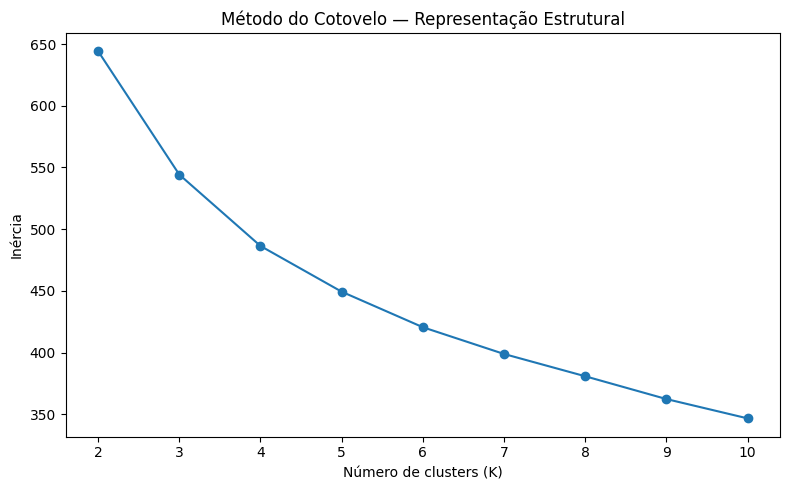

,k,inercia,silhouette_cosine,davies_bouldin,calinski_harabasz
279,2.0,644.262922,0.302783,1.959376,178.495537
280,3.0,544.228114,0.334133,1.701974,178.308142
281,4.0,486.373881,0.335045,1.735220,164.207183
282,5.0,449.310841,0.322099,1.800631,149.437275
283,6.0,420.513434,0.317173,1.768077,138.381470
284,7.0,398.829005,0.321435,1.785175,128.574275
285,8.0,380.769117,0.316078,1.765314,120.619619
286,9.0,362.290908,0.332274,1.706097,115.795393
287,10.0,346.632116,0.335694,1.671667,111.382289


In [ ]:
resultado_kmeans_estrutura = (
    resultados_cluster[
        (resultados_cluster["representacao"] == "Estrutura")
        & (resultados_cluster["algoritmo"] == "KMeans")
    ]
    .sort_values("k")
)

plt.figure(figsize=(8, 5))
plt.plot(
    resultado_kmeans_estrutura["k"],
    resultado_kmeans_estrutura["inercia"],
    marker="o"
)
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inércia")
plt.title("Método do Cotovelo — Representação Estrutural")
plt.xticks(resultado_kmeans_estrutura["k"].astype(int))
plt.tight_layout()
plt.show()

display(
    resultado_kmeans_estrutura[
        [
            "k",
            "inercia",
            "silhouette_cosine",
            "davies_bouldin",
            "calinski_harabasz"
        ]
    ]
)

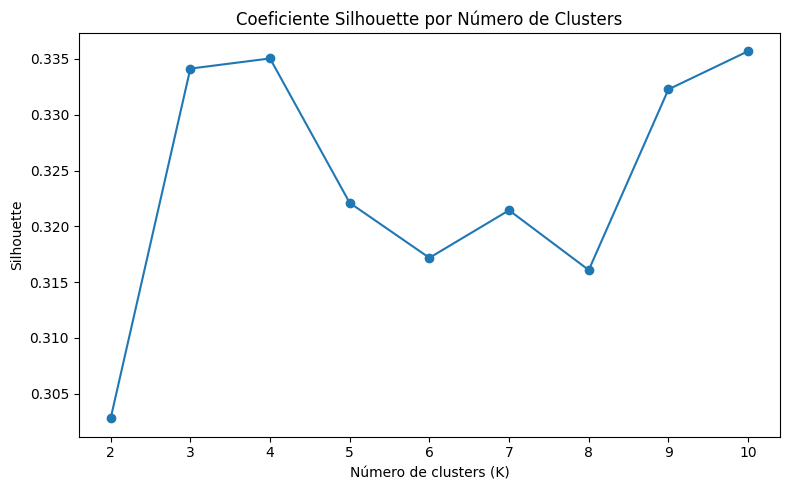

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(
    resultado_kmeans_estrutura["k"],
    resultado_kmeans_estrutura["silhouette_cosine"],
    marker="o"
)
plt.xlabel("Número de clusters (K)")
plt.ylabel("Silhouette")
plt.title("Coeficiente Silhouette por Número de Clusters")
plt.xticks(resultado_kmeans_estrutura["k"].astype(int))
plt.tight_layout()
plt.show()

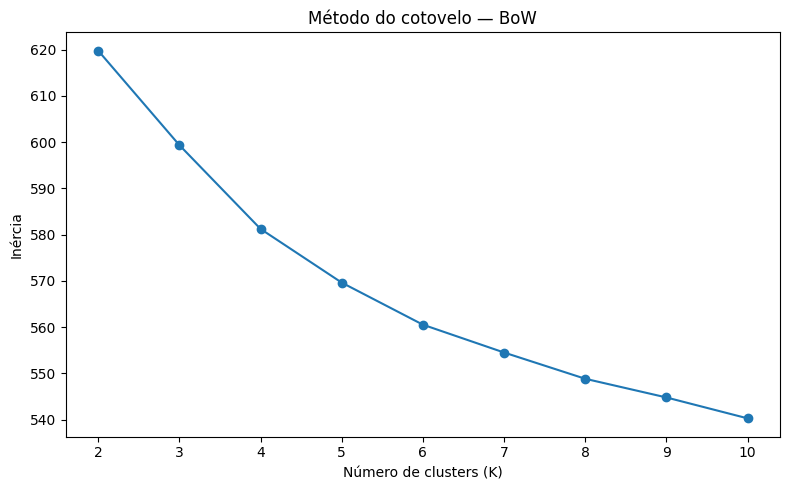

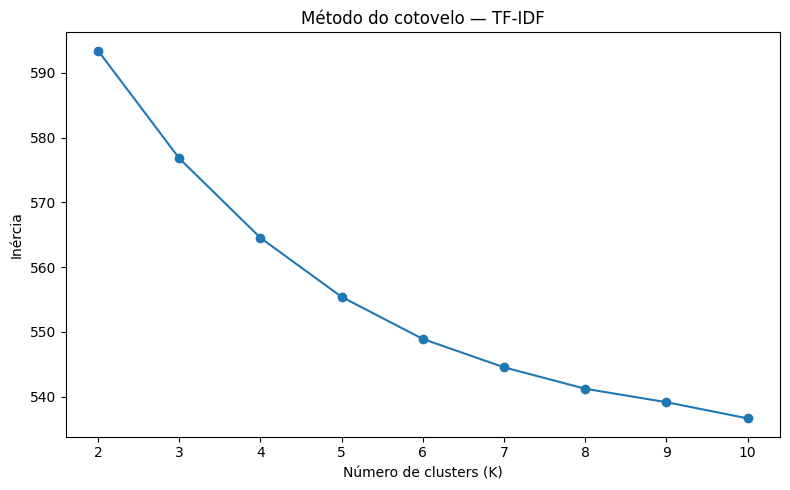

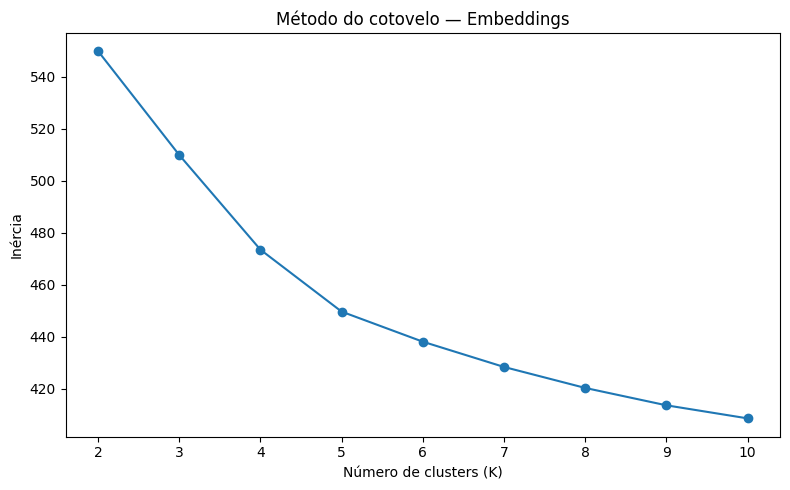

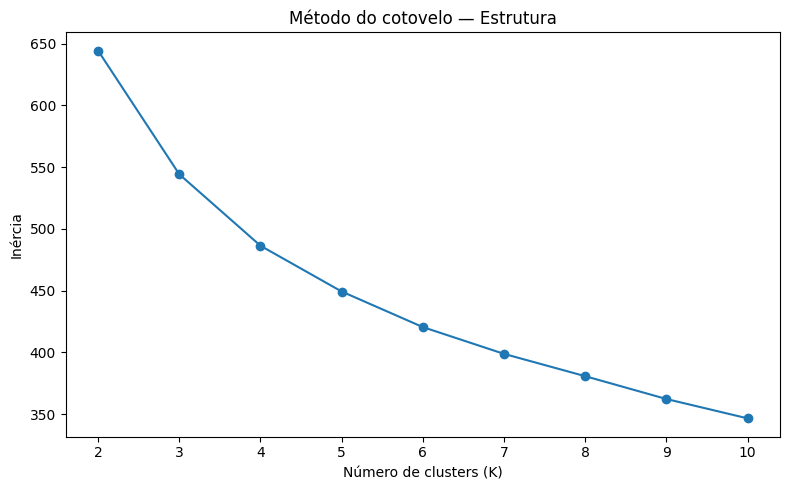

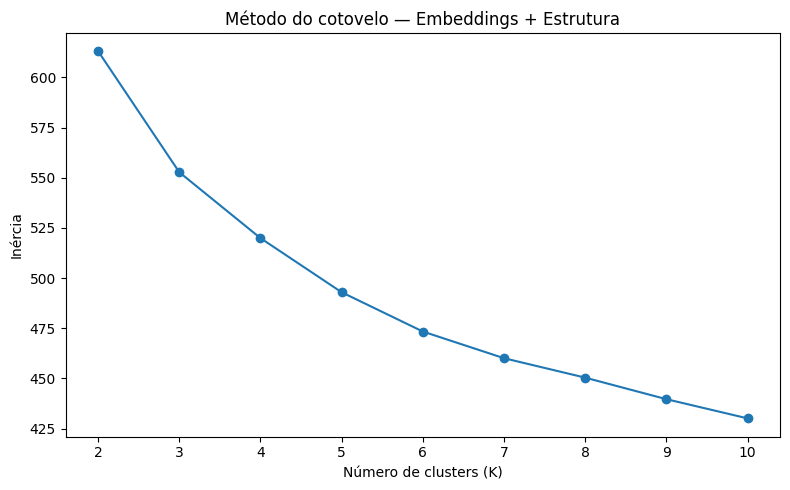

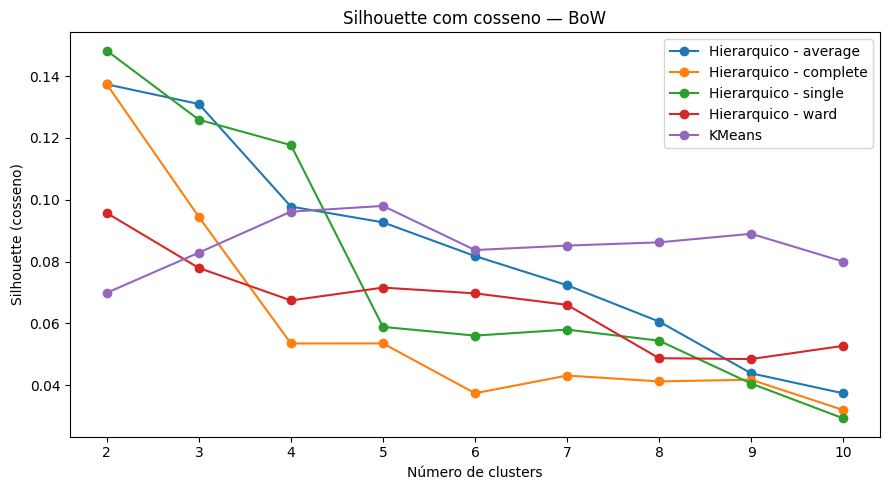

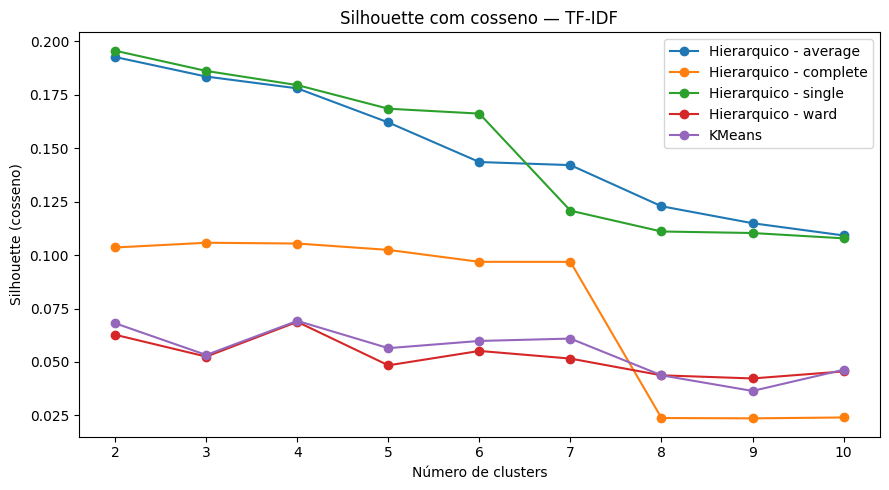

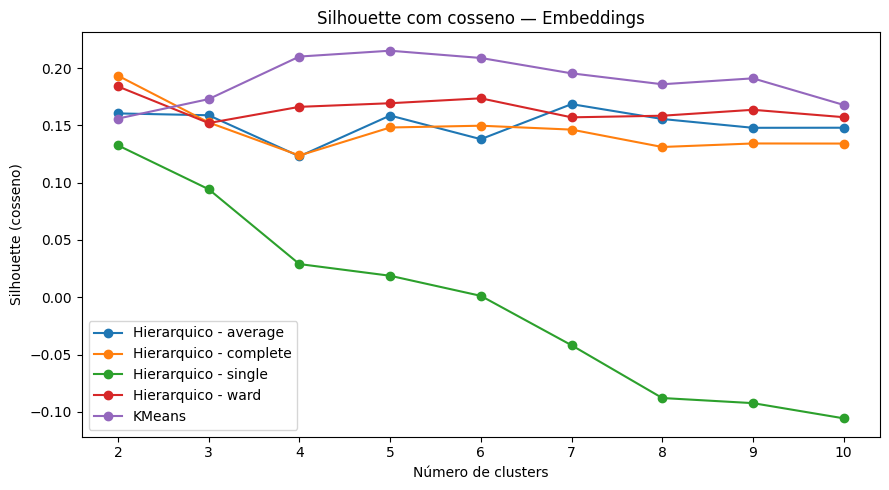

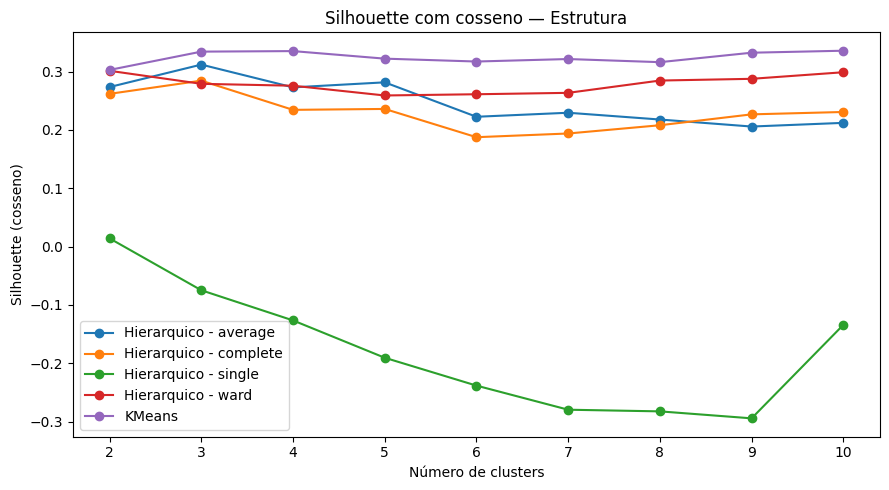

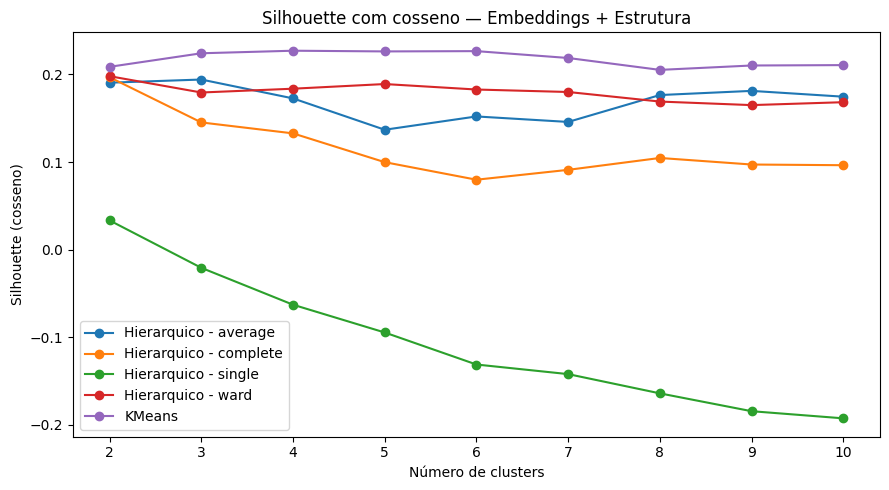

In [ ]:
for representacao in representacoes:
    dados_kmeans = resultados_cluster[
        (resultados_cluster["representacao"] == representacao)
        & (resultados_cluster["algoritmo"] == "KMeans")
        & (resultados_cluster["k"].notna())
    ].sort_values("k")

    plt.figure(figsize=(8, 5))
    plt.plot(
        dados_kmeans["k"],
        dados_kmeans["inercia"],
        marker="o"
    )
    plt.xlabel("Número de clusters (K)")
    plt.ylabel("Inércia")
    plt.title(f"Método do cotovelo — {representacao}")
    plt.tight_layout()
    plt.show()

for representacao in representacoes:
    dados = resultados_cluster[
        (resultados_cluster["representacao"] == representacao)
        & (resultados_cluster["k"].notna())
    ].copy()

    plt.figure(figsize=(9, 5))

    for (algoritmo, linkage_name), grupo in dados.groupby(
        ["algoritmo", "linkage"],
        dropna=False
    ):
        descricao = algoritmo

        if algoritmo == "Hierarquico":
            descricao = f"{algoritmo} - {linkage_name}"

        grupo = grupo.sort_values("k")

        plt.plot(
            grupo["k"],
            grupo["silhouette_cosine"],
            marker="o",
            label=descricao
        )

    plt.xlabel("Número de clusters")
    plt.ylabel("Silhouette (cosseno)")
    plt.title(f"Silhouette com cosseno — {representacao}")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 9. Pipeline final

A configuração final é selecionada entre os modelos válidos pela maior **Silhouette com distância de cosseno**. Davies-Bouldin e Calinski-Harabasz são utilizados como critérios complementares de desempate.

O método do cotovelo deve ser observado em conjunto com a Silhouette na interpretação do número de clusters. A seleção automática não substitui a análise substantiva dos grupos encontrados.

In [ ]:
if ranking_modelos.empty:
    raise ValueError("Nenhuma configuração válida de agrupamento foi encontrada.")

# melhor = ranking_modelos.iloc[0]
K_FINAL = 4

melhor = (
    ranking_modelos[
        (ranking_modelos["representacao"] == "Estrutura")
        & (ranking_modelos["algoritmo"] == "KMeans")
        & (ranking_modelos["k"] == K_FINAL)
    ]
    .iloc[0]
)

representacao_final = melhor["representacao"]

if melhor["algoritmo"] == "KMeans":
    clusterizador_final = KMeans(
        n_clusters=int(melhor["k"]),
        random_state=RANDOM_STATE,
        n_init=30
    )

elif melhor["algoritmo"] == "Hierarquico":
    if melhor["linkage"] == "ward":
        clusterizador_final = AgglomerativeClustering(
            n_clusters=int(melhor["k"]),
            linkage="ward"
        )
    else:
        clusterizador_final = AgglomerativeClustering(
            n_clusters=int(melhor["k"]),
            metric="cosine",
            linkage=melhor["linkage"]
        )

else:
    clusterizador_final = DBSCAN(
        eps=float(melhor["eps"]),
        min_samples=int(melhor["min_samples"]),
        metric="cosine"
    )

X_final = matrizes[representacao_final]
labels_final = clusterizador_final.fit_predict(X_final)
df["cluster_perfil"] = labels_final

print("Representação selecionada:", representacao_final)
print("Algoritmo selecionado:", melhor["algoritmo"])
print("Métrica da clusterização:", melhor["metrica_clusterizacao"])
print("Número de clusters:", int(melhor["n_clusters"]))
print("Cobertura:", round(float(melhor["cobertura"]), 4))
print("Silhouette (cosseno):", round(float(melhor["silhouette_cosine"]), 4))
print("Davies-Bouldin:", round(float(melhor["davies_bouldin"]), 4))
print("Calinski-Harabasz:", round(float(melhor["calinski_harabasz"]), 4))

display(
    df[
        [
            COLUNA_ID,
            COLUNA_PERIODICO,
            "ano_publicacao",
            "cluster_perfil",
            "perfil_metodologico_indicativo"
        ]
    ].head()
)

Representação selecionada: Estrutura
Algoritmo selecionado: KMeans
Métrica da clusterização: euclidean_sobre_vetores_L2
Número de clusters: 4
Cobertura: 1.0
Silhouette (cosseno): 0.335
Davies-Bouldin: 1.7352
Calinski-Harabasz: 164.2072


,arquivo,periodico,ano_publicacao,cluster_perfil,perfil_metodologico_indicativo
0,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,ACM Computing Surveys,2024.0,0,Quantitativo
1,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,ACM Computing Surveys,2024.0,0,Experimental
2,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,ACM Computing Surveys,2024.0,0,Experimental
3,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,ACM Computing Surveys,2024.0,0,Revisão
4,/content/drive/MyDrive/ARTIGOS SELECIONADOS/0 ...,ACM Computing Surveys,2024.0,0,Revisão


## 10. Distribuição dos perfis entre os periódicos

O periódico é utilizado somente nesta etapa, depois da formação dos clusters. A tabela mostra a porcentagem de artigos de cada periódico atribuída a cada perfil identificado.

cluster_perfil,0,1,2,3
periodico,,,,
ACM Computing Surveys,97,0,3,0
Computer Science Review,13,23,50,14
Education and Information Technologies,90,3,1,6
ICT Express,0,49,12,39
IEEE Communications Surveys and Tutorials,6,1,88,0
ISA Transactions,2,32,1,65
Information Sciences,5,22,2,71
Proceedings of the IEEE,5,42,50,3


cluster_perfil,0,1,2,3
periodico,,,,
ACM Computing Surveys,97.00,0.00,3.00,0.0
Computer Science Review,13.00,23.00,50.00,14.0
Education and Information Technologies,90.00,3.00,1.00,6.0
ICT Express,0.00,49.00,12.00,39.0
IEEE Communications Surveys and Tutorials,6.32,1.05,92.63,0.0
ISA Transactions,2.00,32.00,1.00,65.0
Information Sciences,5.00,22.00,2.00,71.0
Proceedings of the IEEE,5.00,42.00,50.00,3.0


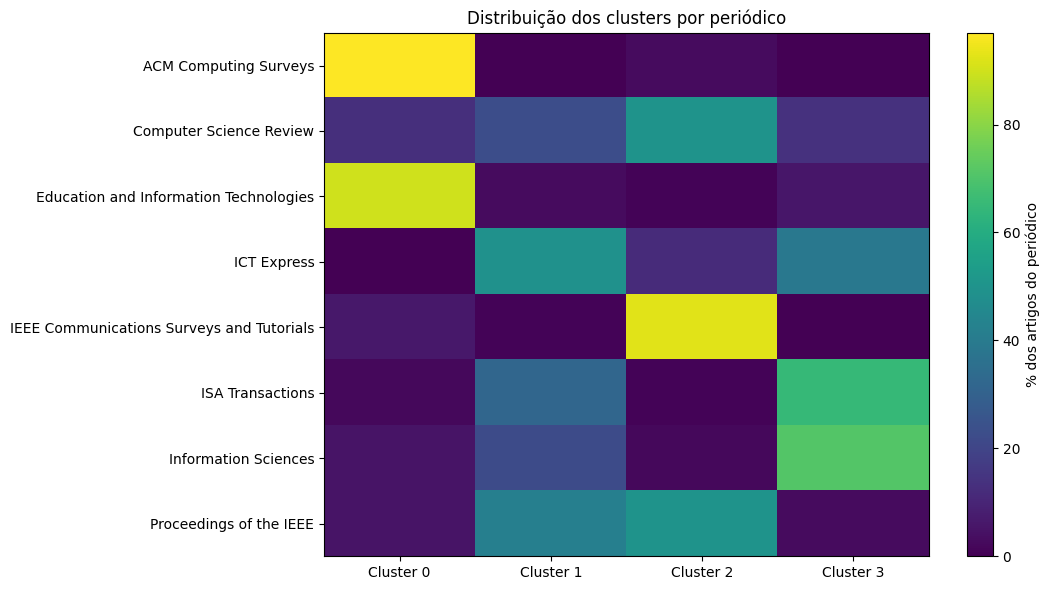

In [ ]:
tabela_periodico_cluster = pd.crosstab(
    df[COLUNA_PERIODICO],
    df["cluster_perfil"],
    normalize="index"
) * 100

contagem_periodico_cluster = pd.crosstab(
    df[COLUNA_PERIODICO],
    df["cluster_perfil"]
)

display(contagem_periodico_cluster)
display(tabela_periodico_cluster.round(2))

plt.figure(figsize=(11, 6))
plt.imshow(tabela_periodico_cluster.values, aspect="auto")
plt.xticks(
    range(len(tabela_periodico_cluster.columns)),
    [f"Cluster {c}" for c in tabela_periodico_cluster.columns]
)
plt.yticks(
    range(len(tabela_periodico_cluster.index)),
    tabela_periodico_cluster.index
)
plt.colorbar(label="% dos artigos do periódico")
plt.title("Distribuição dos clusters por periódico")
plt.tight_layout()
plt.show()

## 11. Caracterização lexical e temática dos clusters

Os termos TF-IDF e as keywords não definem o cluster final. Eles são utilizados depois do agrupamento para interpretar o que diferencia os grupos e verificar se a separação encontrada está fortemente associada a temas específicos.

In [ ]:
preprocessador_interpretacao = AcademicTextPreprocessor(NORMALIZACAO_LEXICAL)
textos_interpretacao = preprocessador_interpretacao.fit_transform(df[COLUNA_TEXTO].tolist())

tfidf_interpretacao = TfidfVectorizer(
    max_features=MAX_FEATURES,
    min_df=MIN_DF,
    max_df=MAX_DF,
    sublinear_tf=True,
    norm="l2"
)

X_tfidf_interpretacao = tfidf_interpretacao.fit_transform(textos_interpretacao)
termos = tfidf_interpretacao.get_feature_names_out()

linhas_termos = []

for cluster_id in sorted(pd.unique(df["cluster_perfil"])):
    if cluster_id == -1:
        continue

    indices = np.flatnonzero(df["cluster_perfil"].to_numpy() == cluster_id)
    media = np.asarray(X_tfidf_interpretacao[indices].mean(axis=0)).ravel()
    top_indices = np.argsort(media)[::-1][:TOP_TERMOS_CLUSTER]

    for ordem, idx in enumerate(top_indices, start=1):
        linhas_termos.append({
            "cluster_perfil": cluster_id,
            "ordem": ordem,
            "termo": termos[idx],
            "tfidf_medio": media[idx]
        })

top_termos_cluster = pd.DataFrame(linhas_termos)
display(top_termos_cluster)

,cluster_perfil,ordem,termo,tfidf_medio
0,0,1,student,0.033704
1,0,2,learning,0.031638
2,0,3,data,0.030799
3,0,4,teacher,0.030434
4,0,5,educational,0.028991
...,...,...,...,...
75,3,16,time,0.028125
76,3,17,paper,0.027983
77,3,18,approach,0.027546
78,3,19,analysis,0.027499


In [ ]:
keywords_cluster_df = (
    df[[COLUNA_ID, COLUNA_PERIODICO, "cluster_perfil", "keywords"]]
    .explode("keywords")
    .dropna(subset=["keywords"])
)

keywords_cluster_df = keywords_cluster_df[
    keywords_cluster_df["keywords"].astype(str).str.strip().ne("")
].copy()

top_keywords_cluster = (
    keywords_cluster_df
    .groupby(["cluster_perfil", "keywords"])
    .size()
    .reset_index(name="frequencia")
    .sort_values(["cluster_perfil", "frequencia"], ascending=[True, False])
    .groupby("cluster_perfil")
    .head(TOP_KEYWORDS_CLUSTER)
    .reset_index(drop=True)
)

display(top_keywords_cluster)

,cluster_perfil,keywords,frequencia
0,0,artificial intelligence,16
1,0,deep learning,14
2,0,generative ai,9
3,0,machine learning,9
4,0,chatgpt,8
5,0,higher education,7
6,0,augmented reality,5
7,0,professional development,5
8,0,blockchain,4
9,0,chatbot,4


## 12. Caracterização estrutural e metodológica dos clusters

Depois da formação dos clusters, os grupos são descritos por indicadores estruturais e pelos perfis metodológicos exploratórios. Essa etapa permite observar, por exemplo, se determinado cluster apresenta maior densidade de figuras e tabelas, maior uso de números ou equações, mais referências ou predominância relativa de artigos experimentais, quantitativos, teóricos, qualitativos ou de revisão.

Como os perfis metodológicos são utilizados somente nesta etapa, eles ajudam a **interpretar** os clusters sem impor previamente essas categorias ao algoritmo de agrupamento.

In [ ]:
COLUNAS_ESTRUTURA_RELATORIO = [
    "n_palavras",
    "n_paginas",
    "n_figuras",
    "n_graficos_estimados",
    "n_tabelas",
    "n_equacoes",
    "n_referencias",
    "figuras_por_1000_palavras",
    "graficos_por_1000_palavras",
    "tabelas_por_1000_palavras",
    "elementos_visuais_por_pagina",
    "equacoes_por_1000_palavras",
    "referencias_por_1000_palavras",
    "citacoes_por_1000_palavras",
    "numeros_por_1000_palavras",
    "proporcao_area_imagens_pdf"
]

resumo_estrutura_cluster = (
    df
    .groupby("cluster_perfil")[COLUNAS_ESTRUTURA_RELATORIO]
    .median()
    .round(4)
)

distribuicao_metodologica_cluster = pd.crosstab(
    df["cluster_perfil"],
    df["perfil_metodologico_indicativo"],
    normalize="index"
) * 100

scores_metodologicos_cluster = (
    df
    .groupby("cluster_perfil")[colunas_scores_metodologicos]
    .mean()
    .round(4)
)

distribuicao_metodologica_periodico = pd.crosstab(
    df[COLUNA_PERIODICO],
    df["perfil_metodologico_indicativo"],
    normalize="index"
) * 100

display(resumo_estrutura_cluster)
display(distribuicao_metodologica_cluster.round(2))
display(scores_metodologicos_cluster)
display(distribuicao_metodologica_periodico.round(2))

,n_palavras,n_paginas,n_figuras,n_graficos_estimados,n_tabelas,n_equacoes,n_referencias,figuras_por_1000_palavras,graficos_por_1000_palavras,tabelas_por_1000_palavras,elementos_visuais_por_pagina,equacoes_por_1000_palavras,referencias_por_1000_palavras,citacoes_por_1000_palavras,numeros_por_1000_palavras,proporcao_area_imagens_pdf
cluster_perfil,,,,,,,,,,,,,,,,
0,11771.5,NaN,6.0,0.0,5.0,0.0,2022.0,0.4888,0.0,0.4405,NaN,0.0000,201.8262,11.3202,69.0391,NaN
1,3920.5,NaN,3.0,0.0,0.0,0.0,0.0,0.7475,0.0,0.0000,NaN,0.0000,0.0000,9.7508,47.5598,NaN
2,27483.0,NaN,12.0,0.0,1.0,0.0,0.0,0.4444,0.0,0.0552,NaN,0.0000,0.0000,18.0550,60.5367,NaN
3,8985.5,NaN,10.0,0.0,5.0,1.5,54.5,1.1586,0.0,0.5904,NaN,0.1814,7.6661,5.5381,101.8003,NaN


perfil_metodologico_indicativo,Experimental,Qualitativo,Quantitativo,Revisão,Teórico
cluster_perfil,,,,,
0,30.73,38.07,6.42,10.55,14.22
1,62.21,6.40,7.56,4.65,19.19
2,58.45,6.76,5.80,4.35,24.64
3,69.19,4.55,7.58,3.54,15.15


,score_metodologico_teorico,score_metodologico_qualitativo,score_metodologico_quantitativo,score_metodologico_experimental,score_metodologico_revisao
cluster_perfil,,,,,
0,0.1411,0.1504,0.1122,0.1399,0.1067
1,0.0796,0.0283,0.0398,0.1114,0.0124
2,0.1080,0.0564,0.0570,0.1358,0.0132
3,0.0980,0.0286,0.0680,0.1389,0.0117


perfil_metodologico_indicativo,Experimental,Qualitativo,Quantitativo,Revisão,Teórico
periodico,,,,,
ACM Computing Surveys,50.00,12.00,6.00,17.00,15.00
Computer Science Review,56.00,6.00,10.00,4.00,24.00
Education and Information Technologies,4.00,76.00,9.00,4.00,7.00
ICT Express,73.00,2.00,6.00,5.00,14.00
IEEE Communications Surveys and Tutorials,50.53,8.42,6.32,2.11,32.63
ISA Transactions,83.00,1.00,4.00,2.00,10.00
Information Sciences,53.00,6.00,9.00,5.00,27.00
Proceedings of the IEEE,65.00,6.00,4.00,8.00,17.00


## 13. Comparação opcional entre texto completo, resumo e introdução

Como embeddings do artigo completo podem capturar fortemente o conteúdo temático, esta análise de sensibilidade compara a separação obtida usando **texto completo**, **resumo** e **introdução**.

A comparação utiliza embeddings normalizados, K-means e Silhouette com distância de cosseno. Ela não altera automaticamente a pipeline principal; serve para verificar se a unidade textual escolhida influencia a formação dos grupos.

Gerando embeddings para o escopo: texto_completo (795 artigos)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Gerando embeddings para o escopo: resumo (348 artigos)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Gerando embeddings para o escopo: introducao (541 artigos)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,escopo,n_artigos,k,silhouette_cosine,inercia
0,introducao,541,5,0.861425,58.449459
1,resumo,348,3,0.586153,132.216232
2,texto_completo,795,5,0.215123,449.623901


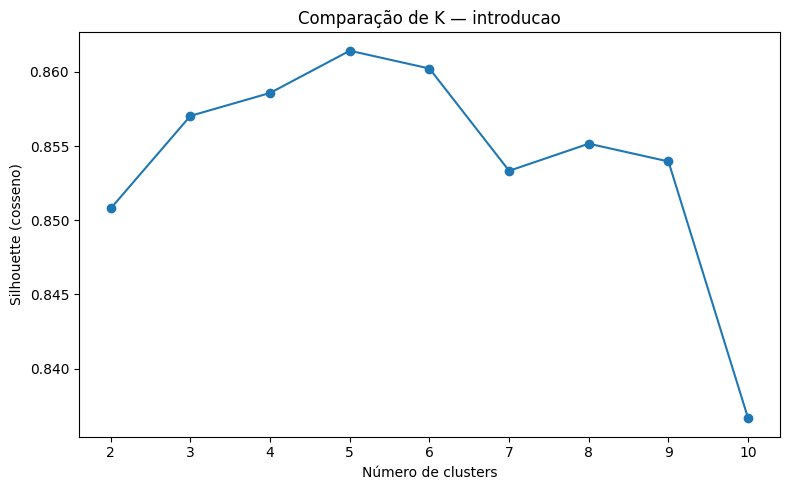

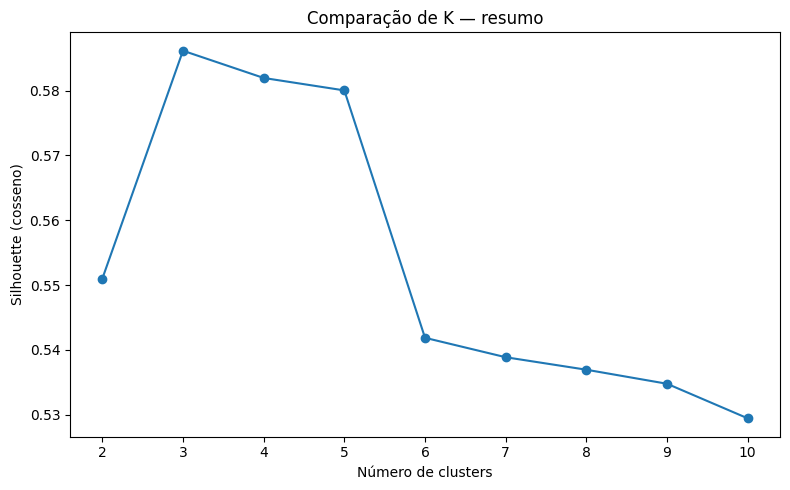

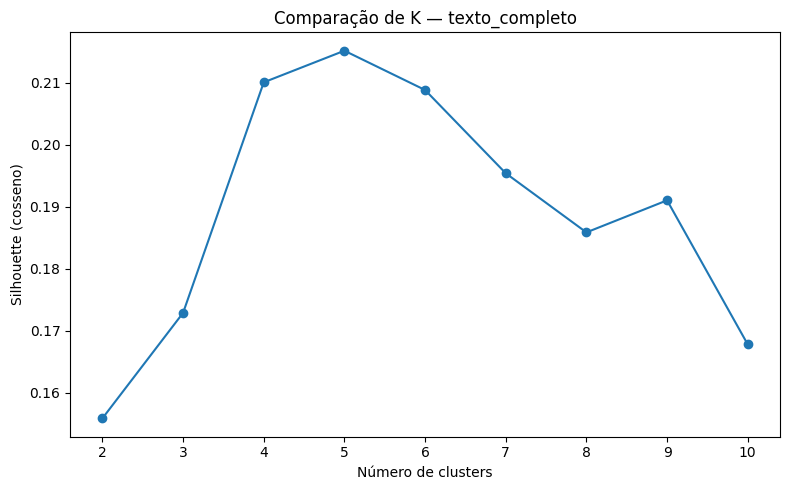

In [ ]:
resultados_escopo = pd.DataFrame()

if EXECUTAR_COMPARACAO_ESCOPO:
    escopos = {
        "texto_completo": df[COLUNA_TEXTO].tolist(),
        "resumo": df["resumo_extraido"].tolist(),
        "introducao": df["introducao_extraida"].tolist()
    }

    linhas_escopo = []

    for nome_escopo, textos_escopo in escopos.items():
        mascara = np.array([
            len(str(texto).split()) >= 30
            for texto in textos_escopo
        ])

        n_validos = int(mascara.sum())

        if n_validos < 50:
            continue

        textos_validos = [
            texto
            for texto, valido in zip(textos_escopo, mascara)
            if valido
        ]

        print(f"Gerando embeddings para o escopo: {nome_escopo} ({n_validos} artigos)")

        representador_escopo = DocumentEmbeddingTransformer()
        X_escopo = representador_escopo.fit_transform(textos_validos)

        for k in range(K_MIN, min(K_MAX, n_validos - 1) + 1):
            modelo = KMeans(
                n_clusters=k,
                random_state=RANDOM_STATE,
                n_init=30
            )

            labels = modelo.fit_predict(X_escopo)

            linhas_escopo.append({
                "escopo": nome_escopo,
                "n_artigos": n_validos,
                "k": k,
                "silhouette_cosine": silhouette_score(
                    X_escopo,
                    labels,
                    metric="cosine"
                ),
                "inercia": modelo.inertia_
            })

    resultados_escopo = pd.DataFrame(linhas_escopo)

    if not resultados_escopo.empty:
        melhores_escopos = (
            resultados_escopo
            .sort_values("silhouette_cosine", ascending=False)
            .groupby("escopo", group_keys=False)
            .head(1)
            .reset_index(drop=True)
        )

        display(melhores_escopos)

        for escopo, grupo in resultados_escopo.groupby("escopo"):
            plt.figure(figsize=(8, 5))
            plt.plot(
                grupo["k"],
                grupo["silhouette_cosine"],
                marker="o"
            )
            plt.xlabel("Número de clusters")
            plt.ylabel("Silhouette (cosseno)")
            plt.title(f"Comparação de K — {escopo}")
            plt.tight_layout()
            plt.show()

## 14. Visualização exploratória

A projeção bidimensional é utilizada apenas para visualização dos documentos. Ela não participa da formação dos clusters.

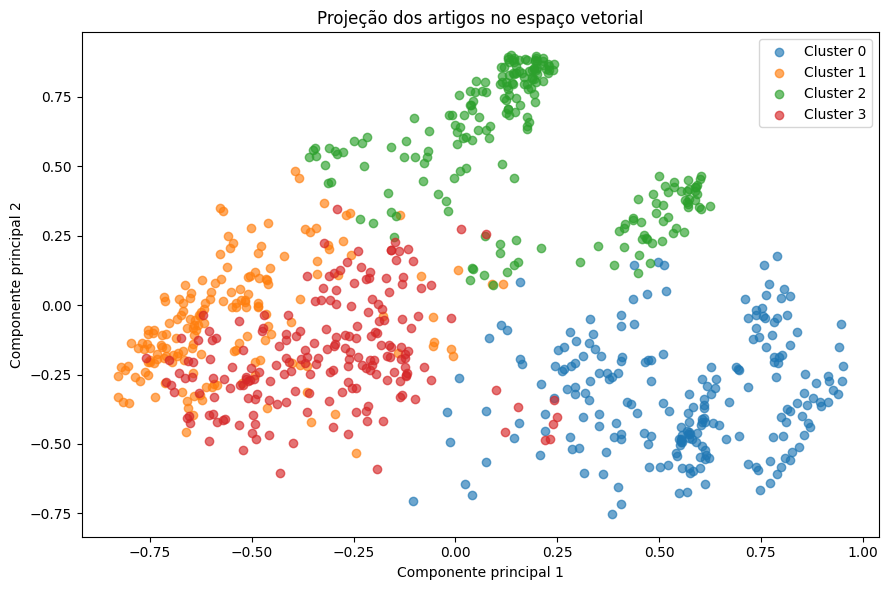

Variância explicada: 0.4002


In [ ]:
X_final_visual = matrizes[representacao_final]

pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_final_visual)

plt.figure(figsize=(9, 6))

for cluster_id in sorted(pd.unique(df["cluster_perfil"])):
    mascara = df["cluster_perfil"].to_numpy() == cluster_id
    nome = "Ruído" if cluster_id == -1 else f"Cluster {cluster_id}"
    plt.scatter(
        coords[mascara, 0],
        coords[mascara, 1],
        alpha=0.65,
        label=nome
    )

plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Projeção dos artigos no espaço vetorial")
plt.legend()
plt.tight_layout()
plt.show()

print("Variância explicada:", round(float(pca.explained_variance_ratio_.sum()), 4))

## 15. Dendrograma auxiliar

O dendrograma permite observar a estrutura hierárquica dos artigos na representação selecionada, independentemente do algoritmo escolhido como configuração final.

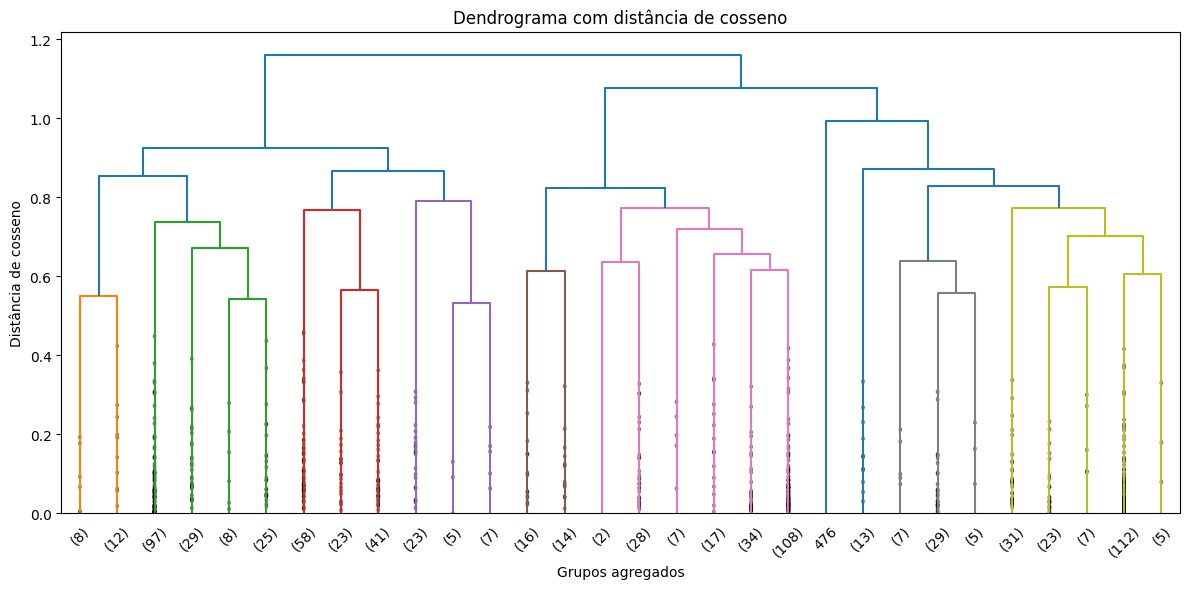

In [ ]:
Z = linkage(
    X_final_visual,
    method="average",
    metric="cosine"
)

plt.figure(figsize=(12, 6))
dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=45,
    show_contracted=True
)
plt.title("Dendrograma com distância de cosseno")
plt.xlabel("Grupos agregados")
plt.ylabel("Distância de cosseno")
plt.tight_layout()
plt.show()

## 16. Exportação dos resultados

In [ ]:
df_exportacao = df.copy()
df_exportacao["keywords"] = df_exportacao["keywords"].map(lambda x: " | ".join(x))
df_exportacao["temas_resumo"] = df_exportacao["temas_resumo"].map(lambda x: " | ".join(x))

perfis_metodologicos_artigos = df[
    [
        COLUNA_ID,
        COLUNA_PERIODICO,
        "ano_publicacao",
        "cluster_perfil",
        "perfil_metodologico_indicativo",
        "margem_perfil_metodologico"
    ]
    + colunas_scores_metodologicos
].copy()

indicadores_estruturais_exportacao = df[
    [COLUNA_ID, COLUNA_PERIODICO, "ano_publicacao", "cluster_perfil"]
    + list(indicadores_estruturais.columns)
].copy()

arquivos_saida = {
    "artigos_clusters": SAIDA_DIR / "artigos_clusters.csv",
    "distribuicao_periodicos": SAIDA_DIR / "distribuicao_periodicos.csv",
    "distribuicao_anos": SAIDA_DIR / "distribuicao_anos.csv",
    "keywords_gerais": SAIDA_DIR / "keywords_gerais.csv",
    "keywords_periodico": SAIDA_DIR / "keywords_por_periodico.csv",
    "keywords_comuns": SAIDA_DIR / "keywords_comuns_periodicos.csv",
    "jaccard_keywords": SAIDA_DIR / "similaridade_keywords_periodicos.csv",
    "temas_resumo": SAIDA_DIR / "temas_resumo.csv",
    "avaliacao_clusterizacao": SAIDA_DIR / "avaliacao_clusterizacao.csv",
    "ranking_modelos": SAIDA_DIR / "ranking_modelos.csv",
    "periodico_cluster": SAIDA_DIR / "distribuicao_periodico_cluster.csv",
    "top_termos_cluster": SAIDA_DIR / "top_termos_cluster.csv",
    "top_keywords_cluster": SAIDA_DIR / "top_keywords_cluster.csv",
    "indicadores_estruturais": SAIDA_DIR / "indicadores_estruturais_artigos.csv",
    "perfis_metodologicos_artigos": SAIDA_DIR / "perfis_metodologicos_artigos.csv",
    "estrutura_cluster": SAIDA_DIR / "resumo_estrutura_clusters.csv",
    "perfil_metodologico_cluster": SAIDA_DIR / "distribuicao_perfil_metodologico_cluster.csv",
    "scores_metodologicos_cluster": SAIDA_DIR / "scores_metodologicos_cluster.csv",
    "perfil_metodologico_periodico": SAIDA_DIR / "distribuicao_perfil_metodologico_periodico.csv",
    "comparacao_escopos": SAIDA_DIR / "comparacao_escopos.csv",
    "configuracao_final": SAIDA_DIR / "configuracao_final.json"
}

df_exportacao.to_csv(arquivos_saida["artigos_clusters"], index=False)
distribuicao_periodicos.to_csv(arquivos_saida["distribuicao_periodicos"], index=False)
distribuicao_ano.to_csv(arquivos_saida["distribuicao_anos"], index=False)
top_keywords.to_csv(arquivos_saida["keywords_gerais"], index=False)
top_keywords_periodico.to_csv(arquivos_saida["keywords_periodico"], index=False)
resumo_comuns.to_csv(arquivos_saida["keywords_comuns"])
jaccard_keywords.to_csv(arquivos_saida["jaccard_keywords"])
frequencia_temas_resumo.to_csv(arquivos_saida["temas_resumo"], index=False)
resultados_cluster.to_csv(arquivos_saida["avaliacao_clusterizacao"], index=False)
ranking_modelos.to_csv(arquivos_saida["ranking_modelos"], index=False)
tabela_periodico_cluster.to_csv(arquivos_saida["periodico_cluster"])
top_termos_cluster.to_csv(arquivos_saida["top_termos_cluster"], index=False)
top_keywords_cluster.to_csv(arquivos_saida["top_keywords_cluster"], index=False)
indicadores_estruturais_exportacao.to_csv(arquivos_saida["indicadores_estruturais"], index=False)
perfis_metodologicos_artigos.to_csv(arquivos_saida["perfis_metodologicos_artigos"], index=False)
resumo_estrutura_cluster.to_csv(arquivos_saida["estrutura_cluster"])
distribuicao_metodologica_cluster.to_csv(arquivos_saida["perfil_metodologico_cluster"])
scores_metodologicos_cluster.to_csv(arquivos_saida["scores_metodologicos_cluster"])
distribuicao_metodologica_periodico.to_csv(arquivos_saida["perfil_metodologico_periodico"])

if isinstance(resultados_escopo, pd.DataFrame) and not resultados_escopo.empty:
    resultados_escopo.to_csv(arquivos_saida["comparacao_escopos"], index=False)

configuracao_final = {
    "arquivo_entrada": caminho_csv,
    "representacao": representacao_final,
    "algoritmo": melhor["algoritmo"],
    "metrica_clusterizacao": melhor["metrica_clusterizacao"],
    "metrica_principal_avaliacao": "silhouette_cosine",
    "k": None if pd.isna(melhor["k"]) else int(melhor["k"]),
    "linkage": None if pd.isna(melhor["linkage"]) else melhor["linkage"],
    "eps": None if pd.isna(melhor["eps"]) else float(melhor["eps"]),
    "min_samples": None if pd.isna(melhor["min_samples"]) else int(melhor["min_samples"]),
    "n_clusters": int(melhor["n_clusters"]),
    "cobertura": float(melhor["cobertura"]),
    "silhouette_cosine": float(melhor["silhouette_cosine"]),
    "davies_bouldin": None if pd.isna(melhor["davies_bouldin"]) else float(melhor["davies_bouldin"]),
    "calinski_harabasz": None if pd.isna(melhor["calinski_harabasz"]) else float(melhor["calinski_harabasz"]),
    "normalizacao_lexical": NORMALIZACAO_LEXICAL,
    "modelo_embedding": MODELO_EMBEDDING,
    "peso_embedding_hibrido": PESO_EMBEDDING_HIBRIDO,
    "peso_estrutura_hibrido": PESO_ESTRUTURA_HIBRIDO,
    "colunas_estrutura_cluster": COLUNAS_ESTRUTURA_CLUSTER,
    "perfis_metodologicos_interpretacao": nomes_perfis,
    "ano_min": ANO_MIN,
    "ano_max": ANO_MAX
}

with open(arquivos_saida["configuracao_final"], "w", encoding="utf-8") as arquivo:
    json.dump(configuracao_final, arquivo, ensure_ascii=False, indent=2)

display(pd.DataFrame({
    "arquivo": arquivos_saida.keys(),
    "caminho": [str(v) for v in arquivos_saida.values()]
}))

,arquivo,caminho
0,artigos_clusters,/content/drive/MyDrive/ARTIGOS SELECIONADOS/re...
1,distribuicao_periodicos,/content/drive/MyDrive/ARTIGOS SELECIONADOS/re...
2,distribuicao_anos,/content/drive/MyDrive/ARTIGOS SELECIONADOS/re...
3,keywords_gerais,/content/drive/MyDrive/ARTIGOS SELECIONADOS/re...
4,keywords_periodico,/content/drive/MyDrive/ARTIGOS SELECIONADOS/re...
5,keywords_comuns,/content/drive/MyDrive/ARTIGOS SELECIONADOS/re...
6,jaccard_keywords,/content/drive/MyDrive/ARTIGOS SELECIONADOS/re...
7,temas_resumo,/content/drive/MyDrive/ARTIGOS SELECIONADOS/re...
8,avaliacao_clusterizacao,/content/drive/MyDrive/ARTIGOS SELECIONADOS/re...
9,ranking_modelos,/content/drive/MyDrive/ARTIGOS SELECIONADOS/re...


## 17. Síntese da pipeline

A pipeline computacional passa a seguir:

**CSV extraído dos PDFs → identificação do periódico → extração/validação do ano → limpeza editorial e remoção de referências → extração de keywords e controle temático → extração de indicadores estruturais → BoW / TF-IDF / embeddings / estrutura / embeddings + estrutura → K-means / Hierárquico / DBSCAN → Elbow + Silhouette com cosseno + métricas complementares → seleção da configuração → comparação entre periódicos → caracterização lexical, estrutural e metodológica dos clusters.**

A representação híbrida utiliza características que descrevem tanto o **conteúdo semântico** quanto a **forma de organização dos artigos**, incluindo extensão, figuras, tabelas, equações, referências, citações, densidade numérica, presença de seções e proporção aproximada de imagens rasterizadas no PDF.

Os perfis **teórico, qualitativo, quantitativo, experimental e revisão** são calculados separadamente por similaridade semântica e utilizados como indicadores de interpretação. Eles **não entram no vetor de clusterização**, evitando que categorias metodológicas previamente definidas determinem artificialmente os grupos encontrados.

As keywords e os temas do resumo também permanecem fora do vetor utilizado na clusterização. Eles funcionam como controles temáticos para verificar se os agrupamentos descobertos estão sendo explicados principalmente pelo assunto dos artigos.